# 02 – Registres publics et réseau

**Développeur 2 :** M'BEY Max  
**Projet :** UE Data Mining 2026-2027 – section destinée au notebook final commun.

**Fichiers de départ :** `registered_entities.csv`, `officer_filings.csv`, `public_appointments.csv`, `licensed_professionals.csv`, `licensed_facilities.csv` (registres), `clinical_encounters.csv`, `clinical_procedures.csv` (santé), `erp_business_partners.csv`, `erp_facilities.csv` (logistique).

**Clés utilisées :**

| Lien | Clé source | Clé cible |
|---|---|---|
| Mandat → organisation | `officer_filings.registration_number` | `registered_entities.registration_number` |
| Établissement → organisation | `licensed_facilities.operating_organization_registration` | `registered_entities.registration_number` |
| Professionnel → établissement | `licensed_professionals.primary_facility_license` | `licensed_facilities.facility_license_number` |
| Rencontre → praticien / lieu | `attending_license_number`, `facility_license_number` | `license_number`, `facility_license_number` |
| Procédure → praticien / lieu | `performing_license_number`, `performing_facility_license` | `license_number`, `facility_license_number` |
| Partenaire ERP → organisation | `erp_business_partners.external_registration_number` | `registered_entities.registration_number` |

**Principe de prudence :** deux noms identiques ou proches ne désignent pas forcément la même personne. Chaque correspondance reçoit un niveau de confiance (**certain**, **probable**, **incertain**) fondé sur des critères explicites : similarité du nom, année de naissance, région, organisation, cohérence des dates. 30 paires ont été vérifiées une à une (§2.5) et le réseau est recalculé avec les seules fusions certaines (§3.3). Les données et le récit sont entièrement fictifs.

## 0. Chargement des données

In [1]:
import re
import unicodedata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from rapidfuzz import fuzz
from unidecode import unidecode

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

DATA = Path("data")
OUT = Path("outputs") / "registres"
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "entities": "public_records/registered_entities.csv",
    "officers": "public_records/officer_filings.csv",
    "appointments": "public_records/public_appointments.csv",
    "professionals": "public_records/licensed_professionals.csv",
    "facilities": "public_records/licensed_facilities.csv",
    "encounters": "health/clinical_encounters.csv",
    "procedures": "health/clinical_procedures.csv",
    "partners": "logistics/erp_business_partners.csv",
    "erp_facilities": "logistics/erp_facilities.csv",
}

# tout lire en texte pour controler soi-meme les conversions de dates et de nombres
raw = {}
for name in FILES:
    raw[name] = pd.read_csv(DATA / FILES[name], dtype=str)

# premier apercu de la taille de chaque fichier
overview = []
for name in raw:
    df = raw[name]
    overview.append({
        "table": name,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "cellules vides": int(df.isna().sum().sum())
    })
pd.DataFrame(overview).set_index("table")

,lignes,colonnes,cellules vides
table,,,
entities,24,10,24
officers,136,12,77
appointments,62,12,77
professionals,53,10,79
facilities,3,12,3
encounters,1069,12,243
procedures,311,14,317
partners,80,11,15
erp_facilities,30,11,1


## 1. Découvrir et nettoyer les registres

Contrôles réalisés avant toute jointure :

1. **Texte** : espaces multiples, espaces en fin de chaîne, casse incohérente (ex. un intitulé de poste entièrement en minuscules).
2. **Dates** : plusieurs formats coexistent (`AAAA-MM-JJ`, `AAAA/MM/JJ`, `JJ/MM/AAAA`). On les convertit avec un parseur qui accepte ces formats, puis on vérifie qu'aucune date non vide n'a été perdue.
3. **Années de naissance** : `officer_filings` contient soit une année (`1961`) soit une tranche (`1920–1929`). On les représente par un intervalle `[birth_min, birth_max]` pour pouvoir comparer prudemment.
4. **Clés et doublons** : unicité des clés primaires, doublons exacts hors identifiant.
5. **Valeurs manquantes** et **incohérences logiques** (fin avant début).

In [2]:
def clean_text(value):
    """
    Retirer les espaces en trop d'une valeur texte.
    Retourne NaN si la valeur est vide.
    """
    if (pd.isna(value)):
        return np.nan
    text = unicodedata.normalize("NFKC", str(value))
    # split puis join supprime les espaces multiples et ceux des extremites
    text = " ".join(text.split())
    if (text == ""):
        return np.nan
    return text


def parse_dates(series):
    """
    Convertir une colonne de dates ecrites dans plusieurs formats
    (AAAA-MM-JJ, AAAA/MM/JJ, JJ/MM/AAAA) en dates pandas.
    """
    # dayfirst ne sert que pour les dates ambigues du type JJ/MM/AAAA
    return pd.to_datetime(series, format="mixed", dayfirst=True, errors="coerce")


def text_issues(df):
    """
    Compter, pour chaque colonne, les valeurs qui changent apres nettoyage.
    """
    rows = []
    for col in df.columns:
        values = df[col].dropna()
        count = 0
        for value in values:
            if (value != clean_text(value)):
                count += 1
        if (count > 0):
            rows.append({"colonne": col, "espaces superflus": count})
    return pd.DataFrame(rows)


for name in ["entities", "officers", "appointments", "professionals", "facilities"]:
    issues = text_issues(raw[name])
    if (len(issues) > 0):
        print(f"--- {name}")
        print(issues.to_string(index=False))

--- officers
  colonne  espaces superflus
full_name                  1
--- appointments
         colonne  espaces superflus
institution_name                  1
--- professionals
  colonne  espaces superflus
specialty                  1


In [3]:
DATE_COLUMNS = {
    "entities": ["registration_date", "last_filing_date"],
    "officers": ["appointment_date", "cessation_date", "filing_date"],
    "appointments": ["appointment_start", "appointment_end"],
    "professionals": ["license_issue_date", "license_expiry_date"],
    "facilities": ["license_start", "license_end"],
    "encounters": ["encounter_start", "encounter_end", "follow_up_date"],
    "procedures": ["scheduled_time", "performed_time", "next_review_date"],
    "partners": ["onboarding_date"],
    "erp_facilities": ["opening_date"],
}

clean = {}
format_report = []
for name in raw:
    df = raw[name].copy()
    # nettoyer toutes les colonnes texte avant de convertir les dates
    for col in df.columns:
        df[col] = df[col].map(clean_text)

    for col in DATE_COLUMNS.get(name, []):
        original = df[col].astype("string")
        # reperer les dates qui ne sont pas au format AAAA-MM-JJ
        iso = original.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)
        non_iso = original.notna() & ~iso
        df[col] = parse_dates(original)
        # une date non vide devenue vide signifierait une conversion ratee
        failed = original.notna() & df[col].isna()
        format_report.append({
            "table": name,
            "colonne": col,
            "valeurs non vides": int(original.notna().sum()),
            "format non ISO": int(non_iso.sum()),
            "exemples non ISO": ", ".join(original[non_iso].head(3)),
            "échecs de conversion": int(failed.sum())
        })
    clean[name] = df

fmt = pd.DataFrame(format_report)
fmt[fmt["format non ISO"] > 0]

,table,colonne,valeurs non vides,format non ISO,exemples non ISO,échecs de conversion
2,officers,appointment_date,136,1,1986/01/01,0
5,appointments,appointment_start,62,1,01/01/1974,0
7,professionals,license_issue_date,53,1,01/07/1994,0
11,encounters,encounter_start,1069,4,"19-Nov-2020 12:15:00, 19/12/2018 09:15:00, 15/02/2021 11...",0
12,encounters,encounter_end,1069,4,"28/12/2021 11:31:00, 06/08/2022 14:01:00, 2021/05/15 13:...",0
13,encounters,follow_up_date,829,2,"2020/02/22, 05-Apr-2023",0
14,procedures,scheduled_time,311,2,"2021/12/06 12:35:00, 09-Jul-2021 11:35:00",0
15,procedures,performed_time,311,1,2021/06/08 09:45:00,0
17,partners,onboarding_date,80,1,01/10/2003,0


In [4]:
print("Échecs de conversion de dates :", int(fmt["échecs de conversion"].sum()))

# un intitule de poste est ecrit entierement en minuscules
officers = clean["officers"]
lower_titles = officers["role_title"].str.match(r"^[a-z]")
print("Intitulés en minuscules :", officers.loc[lower_titles, "role_title"].tolist())
officers.loc[lower_titles, "role_title"] = officers.loc[lower_titles, "role_title"].str.capitalize()


def birth_interval(value):
    """
    Transformer une annee ("1961") ou une tranche ("1920–1929")
    en intervalle (annee_min, annee_max).
    """
    if (pd.isna(value)):
        return (np.nan, np.nan)
    years = []
    for year in re.findall(r"\d{4}", str(value)):
        years.append(int(year))
    return (min(years), max(years))


birth_min = []
birth_max = []
for value in officers["birth_year_or_age_band"]:
    low, high = birth_interval(value)
    birth_min.append(low)
    birth_max.append(high)
officers["birth_min"] = birth_min
officers["birth_max"] = birth_max

# cote nominations l'annee est exacte, donc min = max
appointments = clean["appointments"]
appointments["birth_min"] = pd.to_numeric(appointments["recorded_birth_year"])
appointments["birth_max"] = appointments["birth_min"]
officers[["birth_year_or_age_band", "birth_min", "birth_max"]].drop_duplicates().head(6)

Échecs de conversion de dates : 0
Intitulés en minuscules : ['research director at asterion clinical institute']


,birth_year_or_age_band,birth_min,birth_max
0,1815,1815,1815
1,1871,1871,1871
2,1920–1929,1920,1929
3,1961,1961,1961
4,1862,1862,1862
5,1900,1900,1900


In [5]:
PRIMARY_KEYS = {
    "entities": "registration_number",
    "officers": "filing_id",
    "appointments": "appointment_record_id",
    "professionals": "license_number",
    "facilities": "facility_license_number",
    "encounters": "encounter_number",
    "procedures": "procedure_record_id",
    "partners": "partner_code",
    "erp_facilities": "facility_code",
}

# tableau de qualite : une ligne par fichier
rows = []
for name in PRIMARY_KEYS:
    df = clean[name]
    key = PRIMARY_KEYS[name]
    # un doublon hors cle = meme ligne enregistree deux fois sous deux identifiants
    others = []
    for col in df.columns:
        if (col != key):
            others.append(col)
    n_dates = 0
    n_numbers = 0
    for col in df.columns:
        if (pd.api.types.is_datetime64_any_dtype(df[col])):
            n_dates += 1
        elif (pd.api.types.is_numeric_dtype(df[col])):
            n_numbers += 1
    n_text = df.shape[1] - n_dates - n_numbers
    rows.append({
        "table": name,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "types (date / nombre / texte)": f"{n_dates} / {n_numbers} / {n_text}",
        "% cellules manquantes": round(100 * df.isna().sum().sum() / df.size, 1),
        "doublons exacts": int(df.duplicated().sum()),
        "doublons hors clé": int(df.duplicated(subset=others).sum()),
        "clé": key,
        "clé unique": df[key].is_unique
    })
pd.DataFrame(rows).set_index("table")

,lignes,colonnes,types (date / nombre / texte),% cellules manquantes,doublons exacts,doublons hors clé,clé,clé unique
table,,,,,,,,
entities,24,10,2 / 1 / 7,10.0,0,0,registration_number,True
officers,136,14,3 / 2 / 9,4.0,1,1,filing_id,False
appointments,62,14,2 / 2 / 10,10.9,0,0,appointment_record_id,True
professionals,53,10,2 / 0 / 8,14.9,0,0,license_number,True
facilities,3,12,2 / 0 / 10,8.3,0,0,facility_license_number,True
encounters,1069,12,3 / 0 / 9,1.9,2,2,encounter_number,False
procedures,311,14,3 / 0 / 11,7.3,1,1,procedure_record_id,False
partners,80,11,1 / 0 / 10,1.7,0,0,partner_code,True
erp_facilities,30,11,1 / 0 / 10,0.3,0,0,facility_code,True


In [6]:
dup_cols = []
for col in officers.columns:
    if (col != "filing_id"):
        dup_cols.append(col)

duplicated_rows = officers[officers.duplicated(subset=dup_cols, keep=False)]
duplicated_rows[["filing_id", "officer_local_ref", "full_name", "registration_number",
                 "role_title", "appointment_date", "cessation_date"]]

,filing_id,officer_local_ref,full_name,registration_number,role_title,appointment_date,cessation_date
52,FLG-000053,OFR-20051,Nadia Aren,REG-VLN-01004,Operations manager,2010-01-01,2017-12-31
135,FLG-000053,OFR-20051,Nadia Aren,REG-VLN-01004,Operations manager,2010-01-01,2017-12-31


Les deux lignes ci-dessus sont **strictement identiques**, `filing_id` compris (c'est le doublon exact du tableau de qualité) : il s'agit d'un **double dépôt** du même mandat. On ne conserve que le premier pour ne pas compter deux fois ce mandat dans le réseau et dans les cumuls.

In [7]:
# garder un seul exemplaire du mandat depose deux fois
officers = officers.drop_duplicates(subset=dup_cols, keep="first").reset_index(drop=True)
clean["officers"] = officers

missing = []
for name in ["entities", "officers", "appointments", "professionals", "facilities", "partners"]:
    df = clean[name]
    for col in df.columns:
        n = int(df[col].isna().sum())
        if (n > 0):
            missing.append({
                "table": name,
                "colonne": col,
                "manquants": n,
                "%": round(100 * n / len(df), 1)
            })
pd.DataFrame(missing)

,table,colonne,manquants,%
0,entities,parent_registration_number,24,100.0
1,officers,cessation_date,77,57.0
2,appointments,recorded_birth_year,9,14.5
3,appointments,appointment_end,34,54.8
4,appointments,departure_reason,34,54.8
5,appointments,birth_min,9,14.5
6,appointments,birth_max,9,14.5
7,professionals,license_expiry_date,53,100.0
8,professionals,primary_facility_license,26,49.1
9,facilities,license_end,3,100.0


Lecture des valeurs manquantes :

- `cessation_date` / `appointment_end` / `departure_reason` vides = **mandat en cours** (cohérent avec `filing_status = active`), ce n'est pas une donnée perdue.
- `license_expiry_date` est vide pour **toutes** les licences : aucune licence n'expire, ce qui empêche de vérifier leur validité par la date de fin ; on contrôlera donc la plausibilité par la date de délivrance et l'âge.
- `recorded_birth_year` manque pour 9 nominations ; on pourra l'inférer seulement si un autre enregistrement de la même identité est fiable.
- `parent_registration_number` est vide partout : le registre ne déclare aucune filiale, les liens entre organisations devront venir d'autres indices.

In [8]:
def end_before_start(df, start, end, cols):
    """
    Retourner les lignes dont la date de fin est avant la date de debut.
    """
    has_end = df[end].notna()
    bad = df[has_end & (df[end] < df[start])]
    return bad[cols]


bad_off = end_before_start(officers, "appointment_date", "cessation_date",
                           ["filing_id", "full_name", "registration_number", "role_title",
                            "appointment_date", "cessation_date", "filing_status"])
bad_apt = end_before_start(appointments, "appointment_start", "appointment_end",
                           ["appointment_record_id", "office_holder_name", "office_title",
                            "appointment_start", "appointment_end"])
print(f"Mandats avec fin < début : {len(bad_off)} dépôts, {len(bad_apt)} nominations")
bad_off

Mandats avec fin < début : 9 dépôts, 0 nominations


,filing_id,full_name,registration_number,role_title,appointment_date,cessation_date,filing_status
35,FLG-000036,Calen Uren,REG-NDH-01011,Operations manager,2007-01-01,2006-12-31,historical
49,FLG-000050,Liora Corda,REG-VLN-01002,Regional adviser,2014-01-01,2012-12-31,historical
76,FLG-000077,Jalen Quorin,REG-VLN-01002,Regional adviser,2013-01-01,2011-12-31,historical
83,FLG-000084,Orin Norel,REG-VLN-01005,Senior analyst,1998-01-01,1997-12-31,historical
99,FLG-000100,Pavel Waren,REG-VLN-01021,Programme manager,2011-01-01,2010-12-31,historical
123,FLG-000124,Elian Cevan,REG-VLN-01010,Investigative reporter,2025-01-01,2024-12-31,historical
126,FLG-000127,Daria Garen,REG-VLN-01021,Programme manager,2000-01-01,1998-12-31,historical
128,FLG-000129,Uma Wessen,REG-VLN-01023,Programme manager,2015-01-01,2014-12-31,historical
130,FLG-000131,Petra Koral,REG-VLN-01002,Regional adviser,2005-01-01,2004-12-31,historical


Ces dépôts ont tous une fin **exactement un jour à quelques années avant** le début, avec un statut `historical`. Ce n'est pas corrigeable sans source extérieure (inversion ? date de cessation d'un poste précédent ?). On les **conserve** mais on les marque `date_incoherente = True` : ils ne sont pas utilisés pour calculer des durées ou des chevauchements.

In [9]:
# on garde ces lignes mais on les marque pour les exclure des calculs de duree
officers["date_incoherente"] = officers["filing_id"].isin(bad_off["filing_id"])
appointments["date_incoherente"] = appointments["appointment_record_id"].isin(bad_apt["appointment_record_id"])

Contrôle des **dates dans le futur** : toute date postérieure à la date de référence (dernier dépôt connu dans le registre) est suspecte, sauf les dates de suivi prévues (`follow_up_date`, `next_review_date`).

In [10]:
# date de reference = dernier depot connu dans le registre des entites
ref = clean["entities"]["last_filing_date"].max()
print("Date de référence :", ref.date())

rows = []
for name in DATE_COLUMNS:
    df = clean[name]
    for col in DATE_COLUMNS[name]:
        future = df[df[col] > ref]
        if (len(future) > 0):
            rows.append({
                "table": name,
                "colonne": col,
                "dates futures": len(future),
                "première": future[col].min().date(),
                "dernière": future[col].max().date(),
                "exemple": future.iloc[0, 0]
            })
pd.DataFrame(rows)

Date de référence : 2025-03-31


,table,colonne,dates futures,première,dernière,exemple
0,officers,appointment_date,1,2026-01-01,2026-01-01,FLG-000085
1,officers,filing_date,1,2026-02-21,2026-02-21,FLG-000085
2,professionals,license_issue_date,1,2026-07-01,2026-07-01,LIC-VLN-MED-1006
3,encounters,encounter_start,35,2025-04-02,2026-01-11,ENC-000006
4,encounters,encounter_end,35,2025-04-02,2026-01-11,ENC-000006
5,encounters,follow_up_date,35,2025-04-02,2026-01-11,ENC-000005
6,procedures,scheduled_time,7,2025-05-08,2026-01-11,PRC-000102
7,procedures,performed_time,7,2025-05-08,2026-01-11,PRC-000102
8,procedures,next_review_date,10,2025-04-11,2025-09-07,PRC-000060


**Lecture de la qualité.**

- Les clés sont uniques partout, sauf dans trois fichiers qui contiennent des **lignes copiées à l'identique** : 1 mandat (`FLG-000053`, Nadia Aren), 2 rencontres cliniques (`ENC-000733`, `ENC-000846`) et 1 acte (`PRC-000263`). Le mandat est dédoublonné ci-dessous ; les doublons santé relèvent de la partie santé.
- Le taux de cellules manquantes reste faible (≤ 15 %). Il est surtout dû aux mandats en cours (pas de date de fin), aux licences sans établissement principal et à `parent_registration_number`, vide partout.

**Dates dans le futur** (après le 2025-03-31) :

- le mandat **FLG-000085** de **Farah Havel** chez Asterion commence le **2026-01-01** et a été déposé le 2026-02-21 ;
- sa licence de médecin **LIC-VLN-MED-1006** est délivrée le **2026-07-01** ;
- 35 rencontres cliniques et 7 actes sont datés après la date de référence (jusqu'au 2026-01-11). Ils sont répartis entre plusieurs praticiens, dont 6 rencontres sous la licence de Farah Havel.

Les dates de Farah Havel sont incompatibles avec son activité : elle exerce sous une licence qui n'existe pas encore (§5). Ces lignes sont conservées et signalées, pas corrigées.

Contrôle croisé mandats ↔ registre : un mandat ne devrait pas commencer avant l'enregistrement de l'organisation, ni se poursuivre après sa dissolution.

In [11]:
reg_dates = clean["entities"].set_index("registration_number")
reg_dates = reg_dates[["legal_name", "registration_date", "current_status", "last_filing_date"]]
chk = officers.join(reg_dates, on="registration_number")

chk["avant_enregistrement"] = chk["appointment_date"] < chk["registration_date"]
# un mandat en cours (sans fin) dans une entite dissoute compte aussi comme apres dissolution
end = chk["cessation_date"].fillna(pd.Timestamp.max)
chk["apres_dissolution"] = (chk["current_status"] == "dissolved") & (end > chk["last_filing_date"])
chk["avance_ans"] = ((chk["registration_date"] - chk["appointment_date"]).dt.days / 365.25).round(1)
print("Mandats commençant avant l'enregistrement :", int(chk["avant_enregistrement"].sum()),
      "| mandats après dissolution :", int(chk["apres_dissolution"].sum()))

early = chk[chk["avant_enregistrement"]]
early_summary = early.groupby(["legal_name", "registration_date"]).agg(
    mandats=("filing_id", "size"),
    avance_max_ans=("avance_ans", "max")
)
early_summary.sort_values("avance_max_ans", ascending=False)

Mandats commençant avant l'enregistrement : 49 | mandats après dissolution : 0


,,mandats,avance_max_ans
legal_name,registration_date,,
Earth Ledger Project,2014-01-15,8,27.0
Pollinator Justice Network,2014-01-15,8,27.0
Lantern Investigative Bureau,2015-01-15,5,25.0
Threshold Earth Observatory,2011-01-15,9,25.0
Meridian–Asterion Foundation,2005-01-15,4,23.0
Common Ground Climate Forum,2013-01-15,3,21.0
Northstar Cold Chain Services,1992-01-15,2,18.9
Whitehaven Strategic Holdings,1987-01-15,2,14.0
Valenne Industrial Futures Council,1984-01-15,2,6.7


49 mandats commencent avant l'enregistrement de leur organisation, parfois de plus de 20 ans. Ils sont concentrés dans les organisations militantes, médiatiques ou de recherche enregistrées entre 2011 et 2015 (Earth Ledger Project, Pollinator Justice Network, Lantern Investigative Bureau, Threshold Earth Observatory). L'explication la plus simple est que ces groupes ont existé de manière informelle avant leur enregistrement légal. On ne corrige donc pas ces dates. Elles interdisent seulement d'utiliser « le mandat le plus ancien » comme indicateur du fondateur (cf. §7.1).

## 2. Retrouver les mêmes personnes écrites différemment

### 2.1 Table unique des mentions de personnes

Chaque ligne de `officer_filings`, `public_appointments` et `licensed_professionals` devient une **mention** d'une personne. On garde pour chaque mention le **nom d'origine** et une version normalisée, ainsi que les attributs comparables : intervalle de naissance, région, organisation, date de début et date de fin.

La normalisation passe le nom en minuscules, retire les accents (`unidecode`), la ponctuation, les civilités (`Dr.`, `M.`…) et les espaces multiples. Elle ne change pas l'ordre des mots.

L'**organisation** d'une mention est :

- l'entité du mandat pour `officer_filings` ;
- l'institution pour `public_appointments` ;
- l'organisation qui exploite l'établissement principal pour `licensed_professionals`.

In [12]:
TITLES = ["dr", "prof", "mr", "mrs", "ms", "m", "mme"]


def normalize_name(name):
    """
    Mettre un nom sous une forme comparable : sans accents, sans civilite,
    sans ponctuation, en minuscules.
    """
    text = unidecode(str(name)).lower()
    words = []
    for word in re.findall(r"[a-z]+", text):
        if (word not in TITLES):
            words.append(word)
    return " ".join(words)


professionals = clean["professionals"]
facility_operator = clean["facilities"].set_index("facility_license_number")["operating_organization_registration"]

# une ligne par mention d'une personne, quelle que soit la source
rows = []
for r in officers.itertuples():
    rows.append({
        "source": "officer_filings", "record_id": r.filing_id, "name": r.full_name,
        "birth_min": r.birth_min, "birth_max": r.birth_max, "region": r.nationality_or_region,
        "organisation": r.registration_number,
        "start": r.appointment_date, "end": r.cessation_date, "local_ref": r.officer_local_ref
    })
for r in appointments.itertuples():
    rows.append({
        "source": "public_appointments", "record_id": r.appointment_record_id, "name": r.office_holder_name,
        "birth_min": r.birth_min, "birth_max": r.birth_max, "region": r.official_region,
        "organisation": "INST:" + r.institution_name,
        "start": r.appointment_start, "end": r.appointment_end, "local_ref": np.nan
    })
for r in professionals.itertuples():
    # les licences ne donnent ni l'annee de naissance ni de date de fin
    organisation = np.nan
    if (pd.notna(r.primary_facility_license)):
        organisation = facility_operator[r.primary_facility_license]
    rows.append({
        "source": "licensed_professionals", "record_id": r.license_number, "name": r.professional_name,
        "birth_min": np.nan, "birth_max": np.nan, "region": r.registered_region,
        "organisation": organisation,
        "start": r.license_issue_date, "end": pd.NaT, "local_ref": np.nan
    })
mentions = pd.DataFrame(rows)
mentions["name_norm"] = mentions["name"].map(normalize_name)

print(mentions.groupby("source").agg(mentions=("record_id", "size"), noms_distincts=("name_norm", "nunique")))
mentions[["source", "record_id", "name", "name_norm", "birth_min", "birth_max", "region", "organisation"]].sample(5, random_state=0)

                        mentions  noms_distincts
source                                          
licensed_professionals        53              53
officer_filings              135             104
public_appointments           62              50


,source,record_id,name,name_norm,birth_min,birth_max,region,organisation
225,licensed_professionals,LIC-AVL-ENV-1029,Farah Norel,farah norel,NaN,NaN,Aveloran,REG-AVL-01007
122,officer_filings,FLG-000123,Vera Waren,vera waren,1960.0,1969.0,Aveloran,REG-AVL-01009
92,officer_filings,FLG-000093,Liora Uren,liora uren,1973.0,1973.0,Aveloran,REG-AVL-01007
157,public_appointments,APT-000023,Xara Lask,xara lask,1968.0,1968.0,Kintaran,INST:Office of the Kintara Chancellor
154,public_appointments,APT-000020,Nora Yorin,nora yorin,NaN,NaN,Valennan,INST:Orison Medical Audit Board


In [13]:
# verifier que officer_local_ref designe bien une seule personne (et inversement)
names_by_ref = {}
refs_by_name = {}
for r in officers.itertuples():
    name = normalize_name(r.full_name)
    names_by_ref.setdefault(r.officer_local_ref, set()).add(r.full_name)
    refs_by_name.setdefault(name, set()).add(r.officer_local_ref)

multi = {}
for ref in names_by_ref:
    if (len(names_by_ref[ref]) > 1):
        multi[ref] = sorted(names_by_ref[ref])
print("officer_local_ref associés à plusieurs graphies :", multi)

multi_refs = {}
for name in refs_by_name:
    if (len(refs_by_name[name]) > 1):
        multi_refs[name] = len(refs_by_name[name])
print("Noms normalisés associés à plusieurs officer_local_ref :", multi_refs)

officer_local_ref associés à plusieurs graphies : {}
Noms normalisés associés à plusieurs officer_local_ref : {}


`officer_local_ref` est fiable : une référence correspond toujours à un seul nom (aux espaces près, cf. « Pavel  Waren ») et un nom à une seule référence. On l'utilise donc comme clé dans `officer_filings` : deux dépôts avec la même référence ne sont pas comparés entre eux.

### 2.2 Blocage

Comparer toutes les mentions deux à deux serait inutile : la plupart des paires n'ont rien en commun. On ne garde que les paires **plausibles** :

- les deux mentions viennent de sources différentes, ou de deux déclarants différents de `officer_filings` ;
- elles partagent **l'initiale d'un mot du nom** (prénom ou nom) **ou une année de naissance possible**.

L'initiale d'un mot plutôt que celle du nom de famille rend le blocage insensible à une inversion prénom/nom. On mesure ensuite ce que le blocage fait perdre en le comparant à la comparaison complète.

In [14]:
def block_keys(row):
    """
    Cles de blocage d'une mention : initiale de chaque mot du nom
    et chaque annee de naissance possible.
    """
    keys = set()
    for word in row.name_norm.split():
        keys.add("initiale:" + word[0])
    if (not np.isnan(row.birth_min)):
        for year in range(int(row.birth_min), int(row.birth_max) + 1):
            keys.add("naissance:" + str(year))
    return keys


def comparable(a, b):
    """
    Deux mentions sont a comparer si elles ne viennent pas de la meme source,
    sauf pour officer_filings ou il faut deux declarants differents.
    """
    if (a.source == "officer_filings" and b.source == "officer_filings"):
        return a.local_ref != b.local_ref
    return a.source != b.source


m = mentions.reset_index().rename(columns={"index": "mid"})
rows = list(m.itertuples(index=False))
keys = []
for row in rows:
    keys.append(block_keys(row))

all_pairs = 0
blocked_pairs = []
for i, j in combinations(range(len(rows)), 2):
    if (not comparable(rows[i], rows[j])):
        continue
    all_pairs += 1
    # au moins une cle en commun
    if (len(keys[i] & keys[j]) > 0):
        blocked_pairs.append((i, j))

print(f"Paires comparables : {all_pairs}")
print(f"Paires après blocage : {len(blocked_pairs)} ({100 * len(blocked_pairs) / all_pairs:.1f} %)")

Paires comparables : 27822
Paires après blocage : 5321 (19.1 %)


### 2.3 Score de nom

On utilise `rapidfuzz.fuzz.token_sort_ratio` (0 à 100). Ce score trie les mots avant de comparer : « Jean Dupont » et « Dupont Jean » obtiennent 100. On ne garde que les paires avec un score **≥ 85**.

Pour mesurer la perte due au blocage, on calcule aussi le score sur **toutes** les paires comparables et on liste les paires ≥ 85 que le blocage a écartées.

In [15]:
SCORE_MIN = 85

candidates = []
blocked_set = set()
for i, j in blocked_pairs:
    blocked_set.add((i, j))
    score = fuzz.token_sort_ratio(rows[i].name_norm, rows[j].name_norm)
    if (score >= SCORE_MIN):
        candidates.append((i, j, score))

# controle : les paires >= 85 perdues a cause du blocage
lost = []
for i, j in combinations(range(len(rows)), 2):
    if (not comparable(rows[i], rows[j]) or (i, j) in blocked_set):
        continue
    score = fuzz.token_sort_ratio(rows[i].name_norm, rows[j].name_norm)
    if (score >= SCORE_MIN):
        lost.append({
            "nom_a": rows[i].name, "naissance_a": rows[i].birth_min,
            "nom_b": rows[j].name, "naissance_b": rows[j].birth_min,
            "score": round(score, 1)
        })

print(f"Paires candidates (score ≥ {SCORE_MIN}) : {len(candidates)}")
print(f"Paires ≥ {SCORE_MIN} écartées par le blocage : {len(lost)}")
pd.DataFrame(lost)

Paires candidates (score ≥ 85) : 149
Paires ≥ 85 écartées par le blocage : 7


,nom_a,naissance_a,nom_b,naissance_b,score
0,Yorin Serin,1960.0,Orin Kerin,1956.0,85.7
1,Yorin Serin,1960.0,Orin Kerin,1956.0,85.7
2,Yorin Serin,1960.0,Orin Kerin,NaN,85.7
3,Orin Kerin,1956.0,Yorin Serin,1962.0,85.7
4,Orin Kerin,1956.0,Yorin Serin,1962.0,85.7
5,Taren Yorin,1986.0,Orin Jaren,1961.0,85.7
6,Yorin Serin,1962.0,Orin Kerin,NaN,85.7


Les paires perdues par le blocage associent des personnes dont **le prénom et le nom diffèrent** (*Yorin Serin* / *Orin Kerin*, *Taren Yorin* / *Orin Jaren*). Quand leurs années de naissance sont connues, elles ne concordent pas non plus. Le score élevé vient seulement de terminaisons communes (« -orin », « -en »). Le blocage ne fait donc perdre **aucune correspondance plausible**.

In [16]:
# meme nom de famille mais prenoms differents : ce sont des personnes distinctes
people_by_surname = {}
for name in mentions["name_norm"].unique():
    surname = name.split()[-1]
    if (surname not in people_by_surname):
        people_by_surname[surname] = 0
    people_by_surname[surname] += 1

family = pd.Series(people_by_surname, name="personnes").sort_values(ascending=False)
family.index.name = "nom de famille"
print("Noms de famille portés par au moins 4 personnes différentes :")
print(family[family >= 4].to_string())

Noms de famille portés par au moins 4 personnes différentes :
nom de famille
elen      6
wessen    6
maren     5
uren      5
norel     5
cevan     4
garen     4
aren      4


Beaucoup de noms de famille sont partagés (6 *Wessen*, 6 *Elen*, 5 *Norel*…) et les prénoms sont construits sur les mêmes sons (*Calen / Jalen*, *Orin / Yorin*). Un score de nom élevé ne suffit donc pas : il faut des **indices** indépendants du nom.

### 2.4 Indices et niveaux de confiance

Pour chaque paire candidate on relève des indices **concordants** et **contradictoires** :

| Indice | Concordant si | Contradictoire si |
|---|---|---|
| naissance | intervalles de naissance qui se recouvrent | intervalles disjoints |
| âge | — | la personne aurait moins de 16 ans au début d'un des deux postes ou licences (avec la naissance la plus ancienne possible) |
| chronologie | débuts à moins d'un an d'écart, ou un poste qui commence moins d'un an après la fin de l'autre | — |
| organisation | même organisation ou institution | — |
| nom | — | prénom **ou** nom de famille avec un `fuzz.ratio` < 80 (homonyme partiel, ex. *Calen Uren* / *Calen Garen*) |
| région | — | régions différentes |

Une **même région** n'est pas comptée comme concordante : il n'y a que 5 régions pour 136 personnes, deux inconnus ont donc souvent la même région par hasard.

| Confiance | Règle |
|---|---|
| **certain** | score ≥ 95, au moins un indice concordant, aucun indice contradictoire |
| **probable** | aucun indice contradictoire, et score entre 85 et 95 ou aucun indice concordant |
| **incertain** | au moins un indice contradictoire (homonyme possible) |

Les paires **certaines** et **probables** servent à fusionner les identités (§2.6). Les paires incertaines ne sont jamais fusionnées. Au §3, on mesure ce que changent les paires probables.

In [17]:
ONE_YEAR = pd.Timedelta(366, unit="D")


def close_dates(x, y):
    """
    Vrai si les deux dates existent et sont a moins d'un an d'ecart.
    """
    if (pd.isna(x) or pd.isna(y)):
        return False
    return abs(x - y) <= ONE_YEAR


def pair_evidence(a, b):
    """
    Retourner les listes (indices concordants, indices contradictoires)
    pour deux mentions a et b.
    """
    agree = []
    disagree = []

    first_a, last_a = a.name_norm.rsplit(" ", 1)
    first_b, last_b = b.name_norm.rsplit(" ", 1)
    if (fuzz.ratio(first_a, first_b) < 80 or fuzz.ratio(last_a, last_b) < 80):
        disagree.append("nom différent")

    if (not np.isnan(a.birth_min) and not np.isnan(b.birth_min)):
        if (a.birth_min <= b.birth_max and b.birth_min <= a.birth_max):
            agree.append("naissance compatible")
        else:
            disagree.append("naissance incompatible")

    # naissance la plus ancienne possible : la contradiction doit etre certaine
    births = []
    for value in [a.birth_min, b.birth_min]:
        if (not np.isnan(value)):
            births.append(value)
    if (len(births) > 0):
        earliest = max(births)
        if (a.start.year - earliest < 16 or b.start.year - earliest < 16):
            disagree.append("âge < 16 ans")

    if (close_dates(a.start, b.start) or close_dates(a.end, b.start) or close_dates(b.end, a.start)):
        agree.append("chronologie liée")

    if (pd.notna(a.organisation) and a.organisation == b.organisation):
        agree.append("même organisation")

    if (a.region != b.region):
        disagree.append("région différente")

    return agree, disagree


def confidence_level(score, agree, disagree):
    """
    Appliquer les regles de confiance du tableau ci-dessus.
    """
    if (len(disagree) > 0):
        return "incertain"
    if (score >= 95 and len(agree) > 0):
        return "certain"
    return "probable"


def format_birth(low, high):
    """
    Afficher une annee seule, une tranche, ou rien si la naissance est inconnue.
    """
    if (np.isnan(low)):
        return ""
    if (low == high):
        return str(int(low))
    return f"{low:.0f}–{high:.0f}"


matches_rows = []
for i, j, score in candidates:
    a = rows[i]
    b = rows[j]
    agree, disagree = pair_evidence(a, b)
    indices = []
    for item in agree:
        indices.append("+ " + item)
    for item in disagree:
        indices.append("− " + item)
    matches_rows.append({
        "mention_a": a.mid, "mention_b": b.mid,
        "source_A": a.source, "id_source_A": a.record_id, "nom_A": a.name,
        "naissance_A": format_birth(a.birth_min, a.birth_max),
        "source_B": b.source, "id_source_B": b.record_id, "nom_B": b.name,
        "naissance_B": format_birth(b.birth_min, b.birth_max),
        "score": round(score, 1),
        "indices": " ; ".join(indices),
        "n_concordants": len(agree),
        "n_contradictoires": len(disagree),
        "confiance": confidence_level(score, agree, disagree)
    })
matches = pd.DataFrame(matches_rows)

# libelle court du type de paire, ex. "officer ↔ public"
short_a = matches["source_A"].str.split("_").str[0]
short_b = matches["source_B"].str.split("_").str[0]
matches["paire_sources"] = short_a + " ↔ " + short_b
pd.crosstab(matches["paire_sources"], matches["confiance"], margins=True)

confiance,certain,incertain,probable,All
paire_sources,,,,
officer ↔ licensed,46,13,4,63
officer ↔ officer,0,7,0,7
officer ↔ public,25,17,0,42
public ↔ licensed,25,8,4,37
All,96,45,8,149


In [18]:
cols = ["nom_A", "id_source_A", "naissance_A", "nom_B", "id_source_B", "naissance_B", "score", "indices", "confiance"]
print("Paires probables :")
display(matches[matches["confiance"] == "probable"][cols])
print("Paires incertaines avec un score ≥ 95 :")
display(matches[(matches["confiance"] == "incertain") & (matches["score"] >= 95)][cols])

Paires probables :


,nom_A,id_source_A,naissance_A,nom_B,id_source_B,naissance_B,score,indices,confiance
1,J. Varlan,FLG-000005,1862,J. Varlan,LIC-KNT-RES-1007,,100.0,,probable
5,Mara Venn,FLG-000011,1980–1989,Mara Venn,LIC-VLN-RES-1011,,100.0,,probable
73,Amina Elen,FLG-000096,1964,Amina Elen,LIC-AVL-ENV-1038,,100.0,,probable
102,Daria Garen,FLG-000126,1976,Daria Garen,LIC-NDH-LEG-1049,,100.0,,probable
116,Elira Vaun,APT-000016,1935,Elira Vaun,LIC-AVL-ADM-1013,,100.0,,probable
125,Liora Corda,APT-000026,1990,Liora Corda,LIC-TMB-ADM-1025,,100.0,,probable
132,Jalen Quorin,APT-000038,1989,Jalen Quorin,LIC-TMB-ADM-1034,,100.0,,probable
142,Jalen Havel,APT-000058,1960,Jalen Havel,LIC-VLN-ADM-1050,,100.0,,probable


Paires incertaines avec un score ≥ 95 :


,nom_A,id_source_A,naissance_A,nom_B,id_source_B,naissance_B,score,indices,confiance


### 2.5 Vérification manuelle d'un échantillon

On tire **30 paires** au hasard (graine fixe) réparties sur les trois niveaux : toutes les paires probables, puis des paires certaines et incertaines pour arriver à 30. Pour chacune, on affiche ce que dit chaque source : poste, organisation, période, région.

Le jugement de chaque paire est enregistré dans `verification/verification_manuelle_paires.csv`, avec trois colonnes :

- `verifie_main` : `oui` si c'est la même personne, `non` sinon, `indéterminé` si on ne peut pas trancher ;
- `commentaire` : la raison du jugement ;
- les identifiants `id_source_A` et `id_source_B`.

Ce fichier n'est pas calculé par le notebook : chaque ligne est un jugement argumenté à partir des informations affichées (pas du score), à relire. Le notebook le relit et calcule le taux d'erreur de chaque niveau.

In [19]:
officers_by_id = officers.set_index("filing_id")
appointments_by_id = appointments.set_index("appointment_record_id")
professionals_by_id = professionals.set_index("license_number")


def year_or_empty(date):
    """
    Annee d'une date, ou texte vide si la date manque (poste en cours).
    """
    if (pd.isna(date)):
        return ""
    return f"{date:%Y}"


def describe(source, record_id):
    """
    Resumer en une ligne ce que dit la source sur une mention.
    """
    if (source == "officer_filings"):
        r = officers_by_id.loc[record_id]
        period = f"{r.appointment_date:%Y}–{year_or_empty(r.cessation_date)}"
        return f"{r.role_title} @ {r.registration_number} ({period}) {r.nationality_or_region}"
    if (source == "public_appointments"):
        r = appointments_by_id.loc[record_id]
        period = f"{r.appointment_start:%Y}–{year_or_empty(r.appointment_end)}"
        return f"{r.office_title} @ {r.institution_name} ({period}) {r.official_region}"
    r = professionals_by_id.loc[record_id]
    return (f"{r.profession} / {r.specialty}, délivrée {r.license_issue_date:%Y}, "
            f"{r.primary_facility_license}, {r.registered_region}")


SAMPLE_SIZE = 30
probable = matches[matches["confiance"] == "probable"]
rest = SAMPLE_SIZE - len(probable)
certain = matches[matches["confiance"] == "certain"].sample(rest // 2 + rest % 2, random_state=42)
uncertain = matches[matches["confiance"] == "incertain"].sample(rest // 2, random_state=42)
sample = pd.concat([certain, probable, uncertain])

detail_a = []
detail_b = []
for r in sample.itertuples():
    detail_a.append(describe(r.source_A, r.id_source_A))
    detail_b.append(describe(r.source_B, r.id_source_B))
sample = sample.assign(detail_A=detail_a, detail_B=detail_b)
print(sample["confiance"].value_counts().to_string())
sample[["confiance", "nom_A", "naissance_A", "detail_A", "nom_B", "naissance_B", "detail_B", "indices"]]

confiance
certain      11
incertain    11
probable      8


,confiance,nom_A,naissance_A,detail_A,nom_B,naissance_B,detail_B,indices
126,certain,Petra Grell,1971,Wildlife programme officer @ Kintara Cave and Pollinator...,Petra Grell,,public administration professional / programme administr...,+ chronologie liée
121,certain,Ilia Perin,1967,Accreditation officer @ Orison Medical Audit Board (1992...,Ilia Perin,,public administration professional / programme administr...,+ chronologie liée
114,certain,Dr. Lysa Quen,1968,Senior medical auditor @ Orison Medical Audit Board (199...,Dr. Lysa Quen,,"physician / medical audit, délivrée 1995, FAC-VLN-101, V...",+ chronologie liée
146,certain,Daria Maren,1972,Deputy director @ Avelora Council of State (1996–2000) K...,Daria Maren,,public administration professional / programme administr...,+ chronologie liée
46,certain,Farah Norel,1956,Pollinator advocate @ REG-AVL-01009 (1989–) Aveloran,Farah Norel,,"environmental professional / environmental assessment, d...",+ chronologie liée
123,certain,Xara Lask,1968,Operations manager @ Avelora Council of State (1992–1996...,Xara Lask,,public administration professional / programme administr...,+ chronologie liée
110,certain,Petra Koral,1980–1989,Regional adviser @ REG-VLN-01002 (2005–2004) Tembaran,Petra Koral,,Regional administrative director @ Tembara Coastal Admin...,+ chronologie liée
62,certain,Farah Havel,1994,Specialist clinician @ REG-VLN-01002 (2026–) Valennan,Farah Havel,,"physician / occupational medicine, délivrée 2026, FAC-AV...",+ chronologie liée ; + même organisation
0,certain,Emil Warden,1871,Commercial and medical investor @ REG-VLN-01016 (1895–19...,Emil Warden,,"physician / cardiology, délivrée 1895, FAC-VLN-101, Vale...",+ chronologie liée
12,certain,Daria Zaven,1950–1959,Clinical research scientist @ REG-VLN-01002 (1990–) Vale...,Daria Zaven,,"physician / general medicine, délivrée 1990, FAC-VLN-101...",+ chronologie liée ; + même organisation


In [20]:
VERIFICATION_FILE = Path("verification") / "verification_manuelle_paires.csv"
verification = pd.read_csv(VERIFICATION_FILE, dtype=str)

checked = sample.merge(verification, on=["id_source_A", "id_source_B"], how="left", validate="one_to_one")
# chaque paire tiree doit avoir ete jugee
missing_check = checked[checked["verifie_main"].isna()]
assert len(missing_check) == 0, f"paires non vérifiées : {len(missing_check)}"


def is_error(level, verdict):
    """
    Une erreur : une paire fusionnee (certain/probable) jugee differente,
    ou une paire incertaine jugee identique.
    """
    if (verdict == "indéterminé"):
        return np.nan
    if (level == "incertain"):
        return verdict == "oui"
    return verdict == "non"


errors = []
for r in checked.itertuples():
    errors.append(is_error(r.confiance, r.verifie_main))
checked["erreur"] = errors

rate_rows = []
for level in ["certain", "probable", "incertain"]:
    group = checked[checked["confiance"] == level]
    judged = group["erreur"].dropna()
    rate_rows.append({
        "confiance": level,
        "paires vérifiées": len(group),
        "jugées": len(judged),
        "indéterminées": len(group) - len(judged),
        "erreurs": int(judged.sum()),
        "taux d'erreur estimé": round(judged.mean(), 2) if len(judged) > 0 else np.nan
    })
error_rates = pd.DataFrame(rate_rows)
display(checked[["confiance", "nom_A", "nom_B", "indices", "verifie_main", "commentaire"]])
error_rates

,confiance,nom_A,nom_B,indices,verifie_main,commentaire
0,certain,Petra Grell,Petra Grell,+ chronologie liée,oui,même nom et région ; licence d'administration délivrée l...
1,certain,Ilia Perin,Ilia Perin,+ chronologie liée,oui,même nom et région ; licence d'administration délivrée l...
2,certain,Dr. Lysa Quen,Dr. Lysa Quen,+ chronologie liée,oui,"auditrice médicale nommée en 1995 et licence de médecin,..."
3,certain,Daria Maren,Daria Maren,+ chronologie liée,oui,"licence délivrée en 2001, l'année de sa nomination suiva..."
4,certain,Farah Norel,Farah Norel,+ chronologie liée,oui,militante pollinisateurs depuis 1989 et licence environn...
5,certain,Xara Lask,Xara Lask,+ chronologie liée,oui,"licence délivrée en 1997, l'année de sa nomination suiva..."
6,certain,Petra Koral,Petra Koral,+ chronologie liée,oui,"même nom, région Tembaran, même année 2005 ; même schéma..."
7,certain,Farah Havel,Farah Havel,+ chronologie liée ; + même organisation,oui,même personne : mandat chez Asterion et licence rattaché...
8,certain,Emil Warden,Emil Warden,+ chronologie liée,oui,même personne au XIXe siècle : investisseur médical depu...
9,certain,Daria Zaven,Daria Zaven,+ chronologie liée ; + même organisation,oui,chercheuse clinique chez Asterion depuis 1990 et licence...


,confiance,paires vérifiées,jugées,indéterminées,erreurs,taux d'erreur estimé
0,certain,11,11,0,0,0.0
1,probable,8,8,0,0,0.0
2,incertain,11,11,0,0,0.0


**Résultat de la vérification.** Sur les 30 paires (11 certaines, 8 probables, 11 incertaines), aucune erreur n'a été relevée :

- les 11 paires **certaines** sont toutes la même personne. Le cas typique est une licence délivrée l'année même d'une nomination, dans la même région et le même domaine (ex. Dr. Lysa Quen, auditrice médicale et médecin spécialisée en audit médical depuis 1995) ;
- les 8 paires **probables** sont aussi la même personne. Il leur manque seulement un indice concordant au sens strict des règles (licence délivrée 1 à 2 ans après le début du poste, ou licence de 1965 pour Elira Vaun alors que la nomination comparée commence en 1980). Le niveau *probable* est donc prudent, mais pas faux ;
- les 11 paires **incertaines** sont toutes deux personnes distinctes : noms de famille différents (*Uren / Maren*, *Quorin / Zorin*), ou naissances incompatibles. Le cas le plus délicat est *Daria Maren* / *Daria Garen* : prénom identique et dates proches, mais métiers, régions et licences différents.

Avec 30 paires, un taux d'erreur nul est une estimation fragile, pas une garantie. L'erreur la plus probable serait une paire *probable* qui associe à tort deux homonymes : c'est pour cela que le §3.3 refait le réseau sans elles.

### 2.6 Résolution des identités

On fusionne les mentions par composantes connexes (union-find) en utilisant :

- le même `officer_local_ref` dans `officer_filings` ;
- les paires **certaines** et **probables**.

Chaque groupe reçoit un identifiant `PER-xxx`. L'intervalle de naissance retenu est l'intersection des intervalles connus du groupe. La même résolution est refaite avec **les seules paires certaines**, pour le test de robustesse du §3.

In [21]:
def resolve(pairs_used):
    """
    Regrouper les mentions en personnes (union-find).
    Retourne une Series mid -> person_id.
    """
    parent = list(range(len(m)))

    def find(i):
        while (parent[i] != i):
            # raccourcir le chemin pour les prochaines recherches
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(i, j):
        parent[find(i)] = find(j)

    # meme officer_local_ref = meme declarant
    officer_mentions = m[m["source"] == "officer_filings"]
    for ref, group in officer_mentions.groupby("local_ref"):
        ids = group["mid"].tolist()
        for j in ids[1:]:
            union(ids[0], j)

    for r in pairs_used.itertuples():
        union(r.mention_a, r.mention_b)

    roots = []
    for i in m["mid"]:
        roots.append(find(i))

    # numeroter les personnes dans l'ordre de leur premiere mention
    first_mention = {}
    for i in range(len(roots)):
        if (roots[i] not in first_mention):
            first_mention[roots[i]] = i
    order = sorted(first_mention, key=first_mention.get)
    number = {}
    for k in range(len(order)):
        number[order[k]] = f"PER-{k + 1:03d}"

    person_ids = []
    for root in roots:
        person_ids.append(number[root])
    return pd.Series(person_ids, index=m["mid"])


accepted = matches[matches["confiance"].isin(["certain", "probable"])]
m["person_id"] = resolve(accepted).values
m["person_id_certain"] = resolve(matches[matches["confiance"] == "certain"]).values

rows = []
for person_id, group in m.groupby("person_id"):
    clean_names = []
    for name in group["name"]:
        clean_names.append(" ".join(str(name).split()))
    rows.append({
        "person_id": person_id,
        # nom retenu : la graphie la plus frequente
        "nom": pd.Series(clean_names).mode().iloc[0],
        "graphies": sorted(set(group["name"])),
        "sources": sorted(set(group["source"])),
        "n_mentions": len(group),
        # intersection des intervalles de naissance connus
        "birth_min": group["birth_min"].max(),
        "birth_max": group["birth_max"].min(),
        "regions": sorted(set(group["region"].dropna()))
    })
persons = pd.DataFrame(rows).set_index("person_id")
persons["n_sources"] = persons["sources"].map(len)

print(f"{len(m)} mentions → {len(persons)} personnes "
      f"({m['person_id_certain'].nunique()} avec les seules paires certaines)")
print(persons["n_sources"].value_counts().sort_index().rename("personnes par nombre de sources").to_string())
persons.sort_values(["n_sources", "n_mentions"], ascending=False).head(15)

250 mentions → 136 personnes (141 avec les seules paires certaines)
n_sources
1    71
2    53
3    12


,nom,graphies,sources,n_mentions,birth_min,birth_max,regions,n_sources
person_id,,,,,,,,
PER-026,Liora Maren,[Liora Maren],"[licensed_professionals, officer_filings, public_appoint...",3,1987.0,1987.0,[Kintaran],3
PER-027,Calen Uren,[Calen Uren],"[licensed_professionals, officer_filings, public_appoint...",3,1983.0,1983.0,[Tembaran],3
PER-038,Liora Corda,[Liora Corda],"[licensed_professionals, officer_filings, public_appoint...",3,1990.0,1990.0,[Tembaran],3
PER-047,Petra Grell,[Petra Grell],"[licensed_professionals, officer_filings, public_appoint...",3,1971.0,1971.0,[Kintaran],3
PER-048,Doran Maren,[Doran Maren],"[licensed_professionals, officer_filings, public_appoint...",3,1966.0,1966.0,[Tembaran],3
PER-059,Jalen Quorin,[Jalen Quorin],"[licensed_professionals, officer_filings, public_appoint...",3,1989.0,1989.0,[Tembaran],3
PER-068,Marek Kerin,[Marek Kerin],"[licensed_professionals, officer_filings, public_appoint...",3,1988.0,1988.0,[Kintaran],3
PER-069,Halen Wessen,[Halen Wessen],"[licensed_professionals, officer_filings, public_appoint...",3,1974.0,1974.0,[Tembaran],3
PER-080,Sena Grell,[Sena Grell],"[licensed_professionals, officer_filings, public_appoint...",3,1970.0,1970.0,[Tembaran],3


In [22]:
# confiance du rattachement de chaque mention a sa personne :
# la meilleure confiance obtenue parmi les paires fusionnees qui la concernent
rank = {"certain": 2, "probable": 1}
best = {}
for r in accepted.itertuples():
    for mid in [r.mention_a, r.mention_b]:
        if (mid not in best or rank[r.confiance] > rank[best[mid]]):
            best[mid] = r.confiance

link_confidence = []
for r in m.itertuples():
    if (r.mid in best):
        link_confidence.append(best[r.mid])
    else:
        # mention seule, ou reliee seulement par officer_local_ref : rien d'incertain
        link_confidence.append("certain")
m["confiance_lien"] = link_confidence

# table de correspondances livrable : une ligne par paire candidate
verdict = verification.set_index(["id_source_A", "id_source_B"])
verified = []
for r in matches.itertuples():
    key = (r.id_source_A, r.id_source_B)
    if (key in verdict.index):
        verified.append(verdict.loc[key, "verifie_main"])
    else:
        verified.append("non vérifié")
correspondances = matches[["source_A", "id_source_A", "nom_A", "source_B", "id_source_B", "nom_B",
                           "score", "indices", "confiance"]].copy()
correspondances["vérifié_main"] = verified
correspondances.to_csv(OUT / "table_correspondances.csv", index=False)
m[["person_id", "person_id_certain", "source", "record_id", "name", "confiance_lien"]].to_csv(
    OUT / "mentions_personnes.csv", index=False)
correspondances.sort_values("score", ascending=False).head(10)

,source_A,id_source_A,nom_A,source_B,id_source_B,nom_B,score,indices,confiance,vérifié_main
0,officer_filings,FLG-000002,Emil Warden,licensed_professionals,LIC-VLN-MED-1001,Emil Warden,100.0,+ chronologie liée,certain,oui
110,officer_filings,FLG-000131,Petra Koral,public_appointments,APT-000062,Petra Koral,100.0,+ chronologie liée,certain,oui
108,officer_filings,FLG-000128,Uma Wessen,licensed_professionals,LIC-AVL-RES-1051,Uma Wessen,100.0,+ chronologie liée,certain,non vérifié
106,officer_filings,FLG-000127,Daria Garen,licensed_professionals,LIC-NDH-LEG-1049,Daria Garen,100.0,+ chronologie liée,certain,non vérifié
102,officer_filings,FLG-000126,Daria Garen,licensed_professionals,LIC-NDH-LEG-1049,Daria Garen,100.0,,probable,oui
99,officer_filings,FLG-000124,Elian Cevan,public_appointments,APT-000057,Elian Cevan,100.0,+ naissance compatible ; + chronologie liée,certain,non vérifié
98,officer_filings,FLG-000123,Vera Waren,licensed_professionals,LIC-AVL-ENV-1048,Vera Waren,100.0,+ chronologie liée,certain,oui
97,officer_filings,FLG-000120,Jalen Zorin,licensed_professionals,LIC-AVL-ENV-1047,Jalen Zorin,100.0,+ même organisation,certain,non vérifié
93,officer_filings,FLG-000119,Olia Aren,public_appointments,APT-000056,Olia Aren,100.0,+ naissance compatible ; + chronologie liée,certain,non vérifié
92,officer_filings,FLG-000117,Farah Ferran,licensed_professionals,LIC-TMB-ADM-1046,Farah Ferran,100.0,+ chronologie liée,certain,non vérifié


## 3. Dessiner le réseau

### 3.1 Construction du graphe

Graphe non orienté à quatre types de nœuds (attribut `kind`) :

| Type | Source | Identifiant |
|---|---|---|
| `personne` | identités résolues (§2.6) | `person_id` |
| `organisation` | `registered_entities` | `registration_number` |
| `institution` | `public_appointments.institution_name` (institutions publiques, sans registre) | nom de l'institution |
| `etablissement` | `licensed_facilities` | `facility_license_number` |

Arêtes : mandat (personne–organisation), nomination (personne–institution), licence (personne–établissement principal), exploitation (organisation–établissement).

- Le **poids** d'une arête est le nombre d'enregistrements qui la justifient.
- Sa **confiance** est héritée du §2 : une arête est `certain` si la mention qui la porte est rattachée à sa personne par officer_local_ref ou par une paire certaine, sinon `probable`.

On construit le graphe deux fois : avec toutes les identités fusionnées (certaines + probables), puis avec les seules fusions certaines.

In [23]:
entities = clean["entities"]
facilities = clean["facilities"]
mention_conf = m.set_index(["source", "record_id"])["confiance_lien"]


def build_graph(person_col):
    """
    Construire le graphe personnes - organisations - institutions - etablissements
    a partir de la colonne d'identite person_col de la table m.
    """
    # retrouver la personne a partir de (source, identifiant de la ligne)
    person_of = m.set_index(["source", "record_id"])[person_col]
    graph = nx.Graph()

    for person_id, group in m.groupby(person_col):
        clean_names = []
        for name in group["name"]:
            clean_names.append(" ".join(str(name).split()))
        graph.add_node(person_id, kind="personne", label=pd.Series(clean_names).mode().iloc[0])
    for r in entities.itertuples():
        graph.add_node(r.registration_number, kind="organisation", label=r.legal_name, status=r.current_status)
    # les institutions publiques n'ont pas de numero : on utilise leur nom
    for institution in appointments["institution_name"].unique():
        graph.add_node(f"INST:{institution}", kind="institution", label=institution)
    for r in facilities.itertuples():
        graph.add_node(r.facility_license_number, kind="etablissement", label=r.facility_name)

    def add_edge(u, v, relation, record, confidence):
        if (graph.has_edge(u, v)):
            graph[u][v]["weight"] += 1
            graph[u][v]["records"].append(record)
            # une arete reste certaine si au moins un enregistrement certain la justifie
            if (confidence == "certain"):
                graph[u][v]["confiance"] = "certain"
        else:
            graph.add_edge(u, v, relation=relation, weight=1, records=[record], confiance=confidence)

    for r in officers.itertuples():
        key = ("officer_filings", r.filing_id)
        add_edge(person_of[key], r.registration_number, "mandat", r.filing_id, mention_conf[key])
    for r in appointments.itertuples():
        key = ("public_appointments", r.appointment_record_id)
        add_edge(person_of[key], f"INST:{r.institution_name}", "nomination", r.appointment_record_id, mention_conf[key])
    for r in professionals.itertuples():
        # la moitie des licences n'ont pas d'etablissement principal
        if (pd.notna(r.primary_facility_license)):
            key = ("licensed_professionals", r.license_number)
            add_edge(person_of[key], r.primary_facility_license, "licence", r.license_number, mention_conf[key])
    for r in facilities.itertuples():
        add_edge(r.operating_organization_registration, r.facility_license_number,
                 "exploitation", r.facility_license_number, "certain")
    return graph


G = build_graph("person_id")
G_certain = build_graph("person_id_certain")

pid = m.set_index(["source", "record_id"])["person_id"]
persons_name = persons["nom"]
kinds = pd.Series(nx.get_node_attributes(G, "kind"))
print(G)
print(kinds.value_counts().to_string())
print(pd.Series(nx.get_edge_attributes(G, "relation")).value_counts().to_string())
print("Confiance des arêtes :", pd.Series(nx.get_edge_attributes(G, "confiance")).value_counts().to_dict())

Graph with 171 nodes and 221 edges
personne         136
organisation      24
institution        8
etablissement      3
mandat          131
nomination       60
licence          27
exploitation      3
Confiance des arêtes : {'certain': 213, 'probable': 8}


### 3.2 Centralités, composantes et communautés

- **Degré** : nombre de voisins distincts (pour une personne : nombre d'organisations, institutions ou établissements fréquentés).
- **Intermédiarité** (*betweenness*, normalisée) : part des plus courts chemins qui passent par le nœud. Une personne à forte intermédiarité **relie des groupes** qui, sans elle, ne seraient pas connectés. L'intermédiarité est calculée sur le graphe entier. Elle est nulle entre composantes, donc elle mesure le rôle de pont **à l'intérieur** de chaque composante.
- **Composantes connexes**, puis **communautés de Louvain** (`louvain_communities`, graine fixe pour la reproductibilité).

In [24]:
components = sorted(nx.connected_components(G), key=len, reverse=True)
print("Nombre de composantes :", len(components))

sizes = []
for component in components:
    sizes.append(len(component))
print("Tailles :", sizes)

isolated = []
for component in components[1:]:
    for node in component:
        if (G.nodes[node]["kind"] != "personne"):
            isolated.append(G.nodes[node]["label"])
print("Organisations/établissements hors de la composante principale :", sorted(isolated))

Nombre de composantes : 8
Tailles : [80, 30, 24, 12, 11, 10, 2, 2]
Organisations/établissements hors de la composante principale : ['Asterion Avelora Executive Clinic', 'Asterion Central Clinical Campus', 'Asterion Clinical Institute', 'Avelora Council of State', 'Common Ground Climate Forum', 'Earth Ledger Project', 'Helix Legal and Compliance', 'Meridian BioLogistics', 'Meridian–Asterion Foundation', 'Office of the Kintara Chancellor', 'Orison Medical Audit Board', 'Solvane Energy Group', 'Tembara Biodiversity Service', 'Tembara Coastal Administration', 'Vale Strategy Collective', 'Valenne Industrial Futures Council', 'Vann Maritime Advisory', 'Vosmere Biotechnics', 'Warden Medical Ventures']


In [25]:
def centrality_table(graph):
    """
    Degre et intermediarite de chaque noeud du graphe.
    """
    table = pd.DataFrame({
        "label": pd.Series(nx.get_node_attributes(graph, "label")),
        "type": pd.Series(nx.get_node_attributes(graph, "kind")),
        "degré": pd.Series(dict(graph.degree())),
        "intermédiarité": pd.Series(nx.betweenness_centrality(graph, normalized=True))
    })
    table["intermédiarité"] = table["intermédiarité"].fillna(0).round(3)
    return table


centrality = centrality_table(G)
people = centrality[centrality["type"] == "personne"]
structures = centrality[centrality["type"] != "personne"]
print("Personnes les plus connectées")
display(people.sort_values(["intermédiarité", "degré"], ascending=False).head(12))
print("Organisations / institutions les plus connectées")
display(structures.sort_values("degré", ascending=False).head(12))

Personnes les plus connectées


,label,type,degré,intermédiarité
PER-011,Mara Venn,personne,2,0.060
PER-105,Ilyan Rho,personne,2,0.052
PER-017,Adrienne Solva,personne,2,0.039
PER-036,Jora Vela,personne,3,0.015
PER-057,Zalia Dalen,personne,3,0.015
PER-078,Doran Norel,personne,3,0.015
PER-099,Uma Wessen,personne,3,0.015
PER-111,Dr. Lysa Quen,personne,2,0.014
PER-015,Celene Varro,personne,2,0.009
PER-016,Oskar Nivren,personne,2,0.009


Organisations / institutions les plus connectées


,label,type,degré,intermédiarité
FAC-AVL-301,Threshold Earth Avelora Laboratory,etablissement,20,0.172
REG-VLN-01002,Asterion Clinical Institute,organisation,12,0.015
REG-AVL-01007,Threshold Earth Observatory,organisation,10,0.034
INST:Avelora Ministry of Strategic Resources,Avelora Ministry of Strategic Resources,institution,10,0.032
INST:Avelora Agricultural Resilience Agency,Avelora Agricultural Resilience Agency,institution,10,0.051
REG-VLN-01004,Whitehaven Strategic Holdings,organisation,9,0.039
REG-VLN-01005,Valenne Industrial Futures Council,organisation,9,0.012
INST:Orison Medical Audit Board,Orison Medical Audit Board,institution,9,0.016
REG-VLN-01021,Solvane Energy Group,organisation,9,0.011
REG-VLN-01023,Ardena Capital Union,organisation,9,0.061


In [26]:
LOUVAIN_SEED = 42
communities = nx.community.louvain_communities(G, weight="weight", seed=LOUVAIN_SEED)
modularity = nx.community.modularity(G, communities, weight="weight")
print(f"{len(communities)} communautés de Louvain, modularité = {modularity:.3f}")

comm_rows = []
k = 1
for community in sorted(communities, key=len, reverse=True):
    n_people = 0
    orgs = []
    for node in community:
        G.nodes[node]["community"] = k
        if (G.nodes[node]["kind"] == "personne"):
            n_people += 1
        else:
            orgs.append(G.nodes[node]["label"])
    comm_rows.append({
        "communauté": k,
        "personnes": n_people,
        "organisations / institutions / établissements": "; ".join(sorted(orgs))
    })
    k += 1
pd.DataFrame(comm_rows)

15 communautés de Louvain, modularité = 0.851


,communauté,personnes,organisations / institutions / établissements
0,1,13,Bell Conservation Survey; Marot Ecological Policy Office...
1,2,13,Asterion Avelora Executive Clinic; Asterion Central Clin...
2,3,12,Avelora Ministry of Strategic Resources; Lantern Investi...
3,4,10,Ardena Capital Union; Horizon Field Research Cooperative
4,5,10,Kintara Cave and Pollinator Authority; Pollinator Justic...
5,6,10,Meridian BioLogistics; Valenne Industrial Futures Council
6,7,10,Helix Legal and Compliance; Solvane Energy Group
7,8,10,Avelora Agricultural Resilience Agency; Belen Agro-Indus...
8,9,10,Avelora Council of State; Office of the Kintara Chancellor
9,10,10,Orison Medical Audit Board; Vale Strategy Collective


### 3.3 Robustesse : toutes les fusions ou seulement les certaines

Si un résultat du réseau dépend d'une fusion seulement *probable*, il est fragile. On recalcule donc les mêmes mesures sur `G_certain` et on compare :

- la taille et le nombre de composantes ;
- les communautés (Louvain, même graine) ;
- les 10 personnes de plus forte intermédiarité ;
- les personnes dont l'identité change entre les deux versions.

In [27]:
def summary(graph):
    """
    Quelques mesures globales d'un graphe.
    """
    comps = sorted(nx.connected_components(graph), key=len, reverse=True)
    comms = nx.community.louvain_communities(graph, weight="weight", seed=LOUVAIN_SEED)
    n_people = 0
    for node in graph:
        if (graph.nodes[node]["kind"] == "personne"):
            n_people += 1
    return {
        "personnes": n_people,
        "nœuds": graph.number_of_nodes(),
        "arêtes": graph.number_of_edges(),
        "composantes": len(comps),
        "taille composante principale": len(comps[0]),
        "communautés (Louvain)": len(comms),
        "modularité": round(nx.community.modularity(graph, comms, weight="weight"), 3)
    }


robustness = pd.DataFrame({"toutes les fusions": summary(G), "fusions certaines": summary(G_certain)})
display(robustness)

centrality_certain = centrality_table(G_certain)
top_all = people.nlargest(10, "intermédiarité")["label"].tolist()
people_certain = centrality_certain[centrality_certain["type"] == "personne"]
top_certain = people_certain.nlargest(10, "intermédiarité")["label"].tolist()
print("Top 10 intermédiarité, toutes les fusions :", top_all)
print("Top 10 intermédiarité, fusions certaines   :", top_certain)

common = []
for name in top_all:
    if (name in top_certain):
        common.append(name)
print(f"Personnes communes aux deux top 10 : {len(common)} / 10")

# personnes coupees en plusieurs morceaux quand on ne garde que les fusions certaines
split = m.groupby("person_id")["person_id_certain"].nunique()
split = split[split > 1]
split_rows = []
for person_id in split.index:
    group = m[m["person_id"] == person_id]
    split_rows.append({
        "person_id": person_id,
        "nom": persons_name[person_id],
        "morceaux sans les fusions probables": split[person_id],
        "mentions": "; ".join(group["source"].str.split("_").str[0] + ":" + group["record_id"])
    })
pd.DataFrame(split_rows)

,toutes les fusions,fusions certaines
personnes,136.000,141.00
nœuds,171.000,176.00
arêtes,221.000,222.00
composantes,8.000,11.00
taille composante principale,80.000,67.00
communautés (Louvain),15.000,16.00
modularité,0.851,0.86


Top 10 intermédiarité, toutes les fusions : ['Mara Venn', 'Ilyan Rho', 'Adrienne Solva', 'Jora Vela', 'Zalia Dalen', 'Doran Norel', 'Uma Wessen', 'Dr. Lysa Quen', 'Celene Varro', 'Oskar Nivren']
Top 10 intermédiarité, fusions certaines   : ['Ilyan Rho', 'Adrienne Solva', 'Dr. Lysa Quen', 'Doran Wessen', 'Jora Vela', 'Farah Norel', 'Zalia Dalen', 'Doran Norel', 'Vera Waren', 'Uma Wessen']
Personnes communes aux deux top 10 : 7 / 10


,person_id,nom,morceaux sans les fusions probables,mentions
0,PER-005,J. Varlan,2,officer:FLG-000005; licensed:LIC-KNT-RES-1007
1,PER-011,Mara Venn,2,officer:FLG-000011; licensed:LIC-VLN-RES-1011
2,PER-074,Amina Elen,2,officer:FLG-000096; licensed:LIC-AVL-ENV-1038
3,PER-110,Elira Vaun,2,public:APT-000006; public:APT-000015; public:APT-000016;...
4,PER-134,Jalen Havel,2,public:APT-000058; licensed:LIC-VLN-ADM-1050


**Lecture de la robustesse.**

- Seules **8 arêtes sur 221** reposent sur une fusion probable. Sans ces fusions, 5 personnes sont coupées en deux identités (J. Varlan, Mara Venn, Amina Elen, Elira Vaun, Jalen Havel), et on passe de 136 à 141 personnes.
- La structure générale tient : la modularité reste à ~0,85 et les pôles (médical, logistique, écologie, institutions) restent les mêmes. Le nombre de communautés passe de 15 à 16.
- **Un résultat est fragile** : la composante principale passe de 80 à 67 nœuds. Le pont entre Lantern Investigative Bureau / Avelora Ministry of Strategic Resources et le pôle écologie passe **uniquement par Mara Venn**. Or son rattachement à la licence LIC-VLN-RES-1011 n'est que *probable* (même nom rare et même région, mais aucun indice concordant). Sa première place en intermédiarité dépend donc de cette fusion. Elle est présentée comme une hypothèse, pas comme un fait.
- 7 des 10 personnes de plus forte intermédiarité sont les mêmes dans les deux versions (Ilyan Rho, Adrienne Solva, Dr. Lysa Quen, Jora Vela, Zalia Dalen, Doran Norel, Uma Wessen). Les conclusions qui portent sur ces personnes ne dépendent pas des fusions probables.

### 3.4 Graphes

Le premier graphe montre toutes les composantes. Le second se concentre sur la **composante principale** et n'étiquette que les nœuds clés : les 5 structures de plus haut degré et les 5 personnes de plus forte intermédiarité. Les arêtes `probable` sont en pointillés.

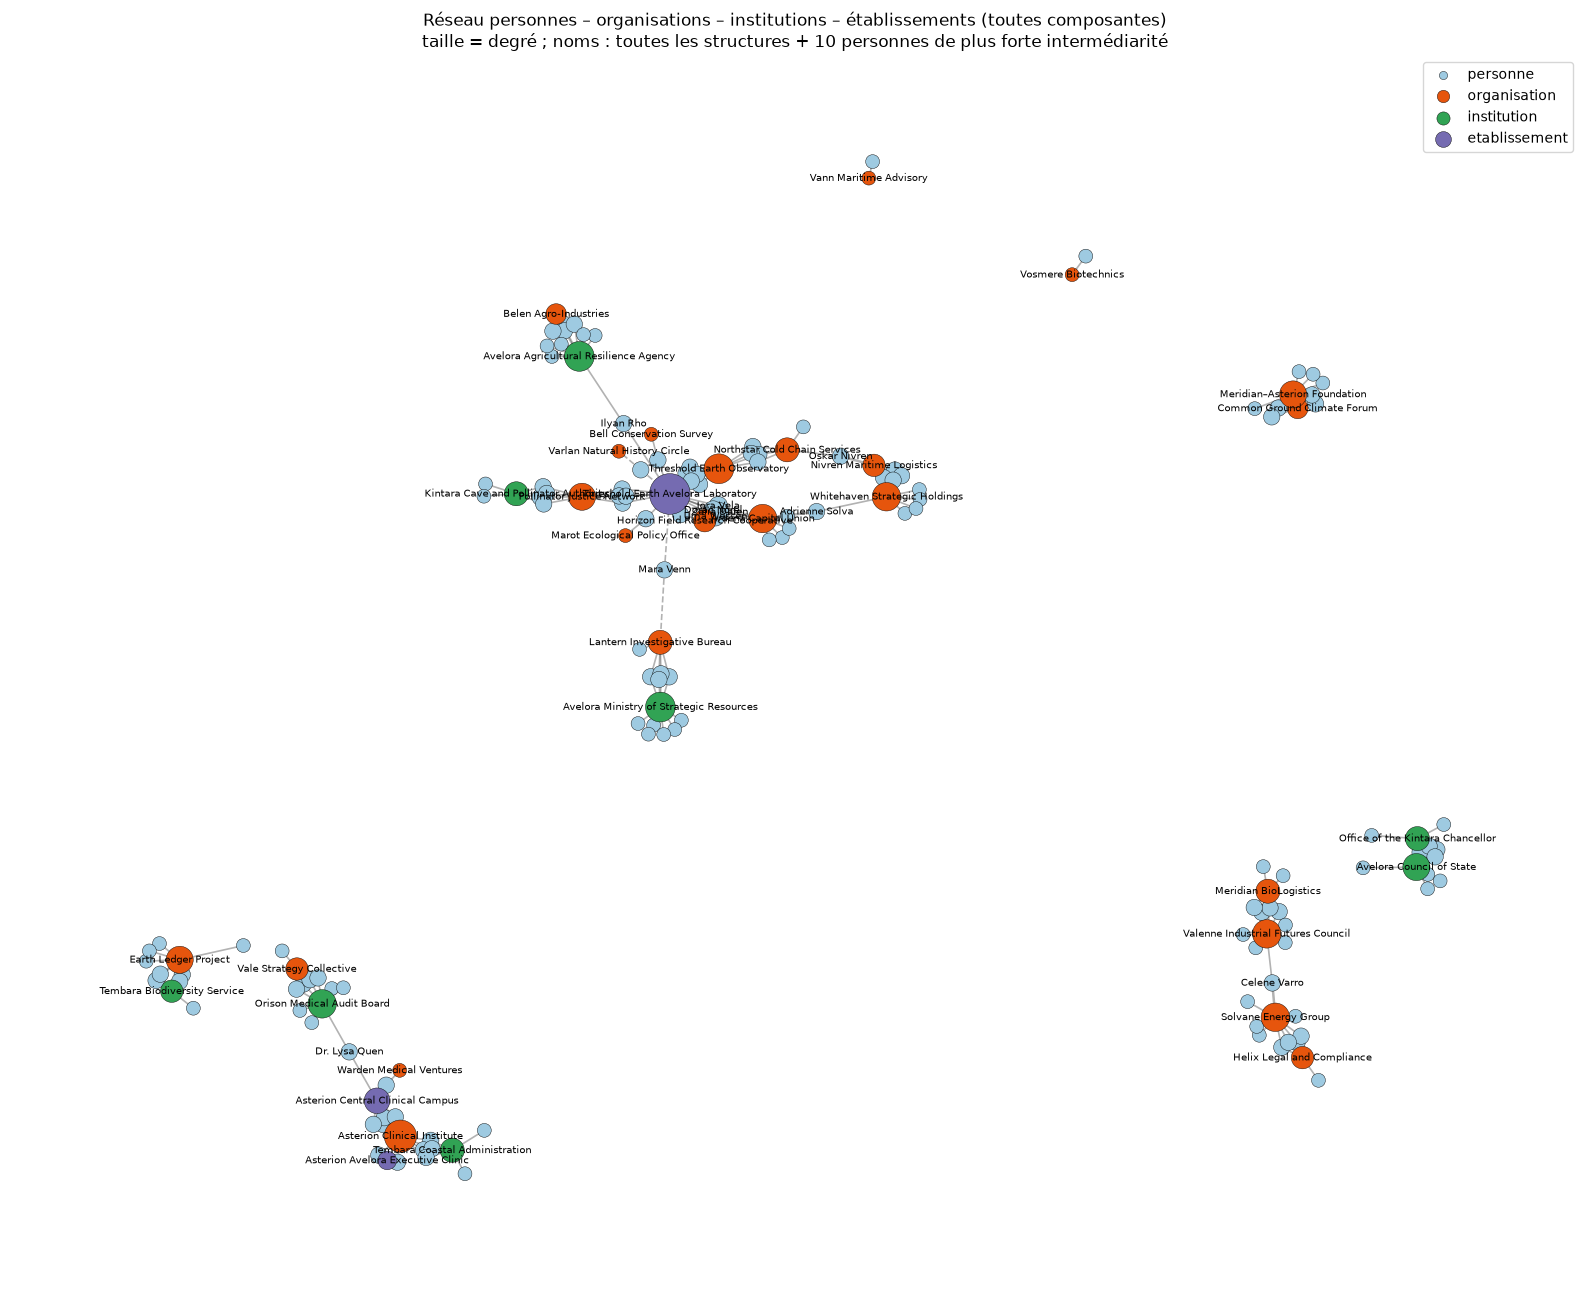

In [28]:
COLORS = {"personne": "#9ecae1", "organisation": "#e6550d", "institution": "#31a354", "etablissement": "#756bb1"}


def draw(graph, ax, labels, title, seed=7):
    """
    Dessiner un graphe : couleur selon le type de noeud, taille selon le degre,
    pointilles pour les aretes probables.
    """
    pos = nx.spring_layout(graph, seed=seed, k=0.3, iterations=300)
    for confidence, style in [("certain", "solid"), ("probable", "dashed")]:
        edges = []
        widths = []
        for u, v, data in graph.edges(data=True):
            if (data["confiance"] == confidence):
                edges.append((u, v))
                widths.append(0.6 + 0.6 * data["weight"])
        nx.draw_networkx_edges(graph, pos, edgelist=edges, ax=ax, alpha=0.3, width=widths, style=style)
    for kind in COLORS:
        nodes = []
        sizes = []
        for node in graph:
            if (graph.nodes[node]["kind"] == kind):
                nodes.append(node)
                # la taille du point grandit avec le nombre de voisins
                sizes.append(60 + 40 * graph.degree(node))
        nx.draw_networkx_nodes(graph, pos, nodelist=nodes, node_color=COLORS[kind], node_size=sizes, ax=ax,
                               label=kind, edgecolors="black", linewidths=0.3)
    nx.draw_networkx_labels(graph, pos, labels=labels, font_size=7, ax=ax)
    ax.set_title(title)
    ax.legend(scatterpoints=1, markerscale=0.5)
    ax.axis("off")


# vue d'ensemble : toutes les structures + 10 personnes qui font le plus le lien
top_people = people.nlargest(10, "intermédiarité").index
labels = {}
for node in G:
    if (G.nodes[node]["kind"] != "personne" or node in top_people):
        labels[node] = G.nodes[node]["label"]
fig, ax = plt.subplots(figsize=(16, 13))
draw(G, ax, labels, "Réseau personnes – organisations – institutions – établissements (toutes composantes)\n"
     "taille = degré ; noms : toutes les structures + 10 personnes de plus forte intermédiarité")
plt.tight_layout()
plt.savefig(OUT / "graphe_registres.png", dpi=150)
plt.show()

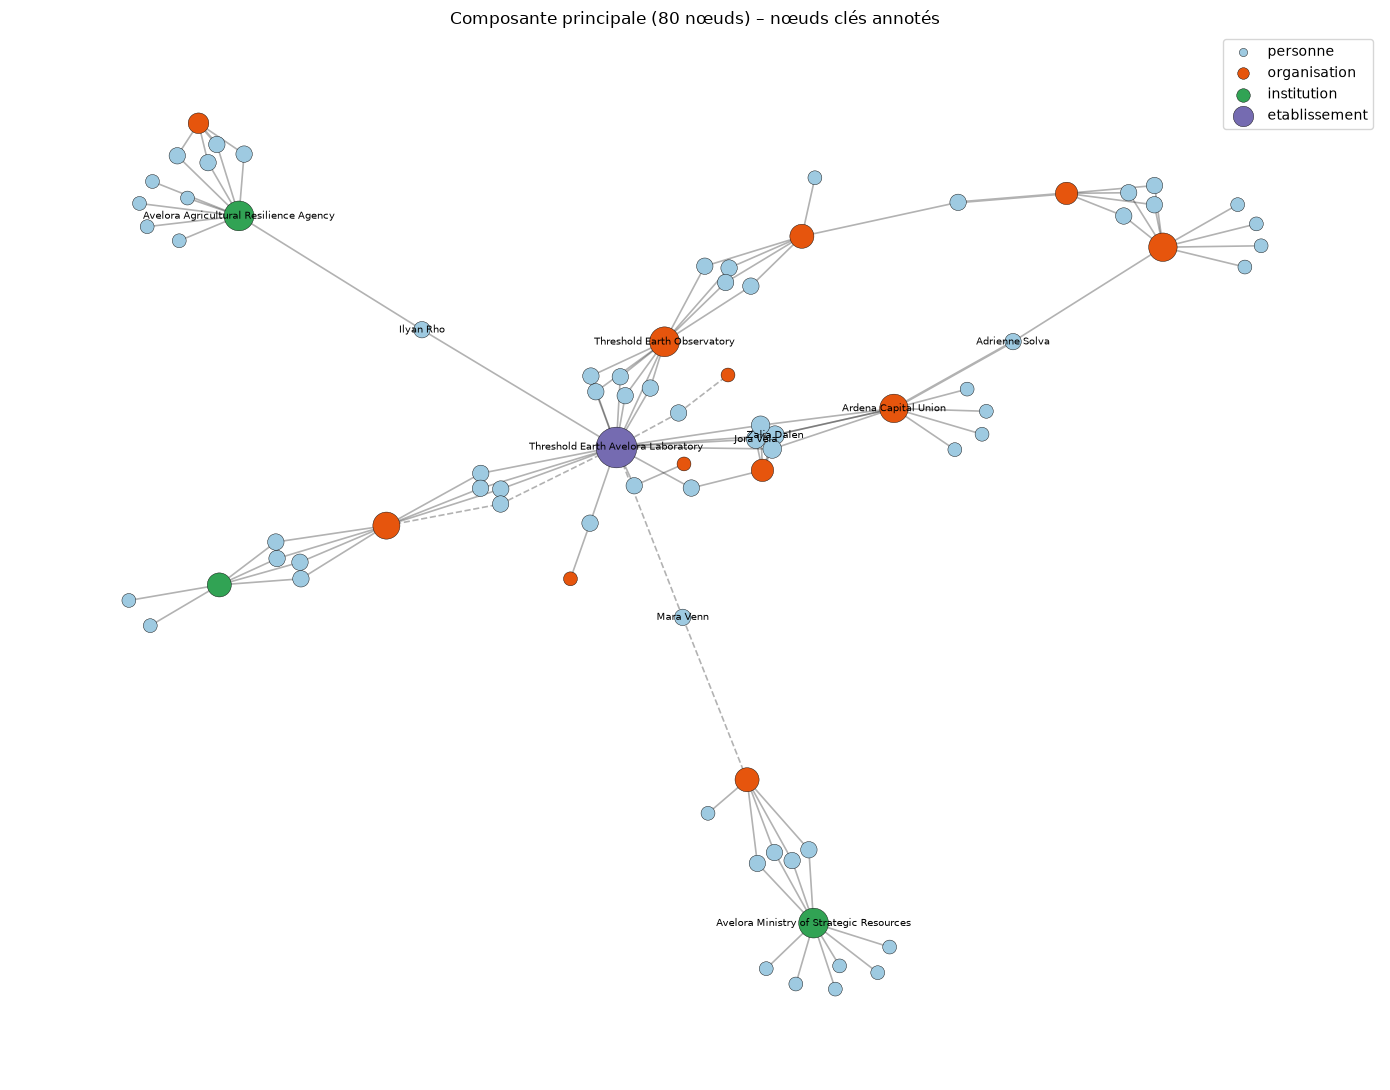

,label,type,degré,intermédiarité
FAC-AVL-301,Threshold Earth Avelora Laboratory,etablissement,20,0.172
REG-AVL-01007,Threshold Earth Observatory,organisation,10,0.034
INST:Avelora Agricultural Resilience Agency,Avelora Agricultural Resilience Agency,institution,10,0.051
INST:Avelora Ministry of Strategic Resources,Avelora Ministry of Strategic Resources,institution,10,0.032
REG-VLN-01023,Ardena Capital Union,organisation,9,0.061
PER-011,Mara Venn,personne,2,0.060
PER-105,Ilyan Rho,personne,2,0.052
PER-017,Adrienne Solva,personne,2,0.039
PER-057,Zalia Dalen,personne,3,0.015
PER-036,Jora Vela,personne,3,0.015


In [29]:
giant = G.subgraph(components[0]).copy()
giant_table = centrality.loc[list(giant.nodes)]
key_structures = giant_table[giant_table["type"] != "personne"].nlargest(5, "degré").index
key_people = giant_table[giant_table["type"] == "personne"].nlargest(5, "intermédiarité").index

labels = {}
for node in list(key_structures) + list(key_people):
    labels[node] = G.nodes[node]["label"]
fig, ax = plt.subplots(figsize=(14, 11))
draw(giant, ax, labels, f"Composante principale ({giant.number_of_nodes()} nœuds) – nœuds clés annotés", seed=3)
plt.tight_layout()
plt.savefig(OUT / "graphe_composante_principale.png", dpi=150)
plt.show()
giant_table.loc[list(key_structures) + list(key_people)]

**Lecture du graphe.**

- Le réseau est **fragmenté** : 8 composantes. La plus grande (80 nœuds) regroupe l'écosystème écologie / agriculture / activisme d'Avelora et de Kintara. Son centre est l'établissement **Threshold Earth Avelora Laboratory** (degré 20, intermédiarité maximale 0,17), auquel sont rattachées presque toutes les licences environnementales et de recherche.
- Le pôle **médical** forme une composante séparée (30 nœuds) : Asterion Clinical Institute, ses deux établissements, l'**Orison Medical Audit Board**, la Tembara Coastal Administration, Vale Strategy Collective et Warden Medical Ventures. L'organisme d'audit médical est relié à l'établissement qu'il devrait contrôler par **Dr. Lysa Quen**, à la fois *Senior medical auditor* (nomination publique depuis 1995) et médecin rattaché à l'Asterion Central Clinical Campus.
- Le pôle **logistique / industrie** (Meridian BioLogistics, Valenne Industrial Futures Council, Solvane Energy Group, Helix Legal) forme une troisième composante. Il est relié au lobby industriel par d'anciens cadres (Vera Faron, Nora Essen, Alina Istra) et par **Celene Varro** (PDG de Solvane et membre du conseil industriel).
- Les personnes de plus forte intermédiarité sont des **passeurs** : **Mara Venn** (« ancienne employée de la recherche-logistique et source indépendante ») relie Lantern Investigative Bureau au laboratoire Threshold Earth (par une fusion seulement *probable*, cf. §3.3), **Ilyan Rho** relie l'agence agricole au laboratoire, et **Adrienne Solva** relie Ardena Capital Union à Whitehaven Strategic Holdings.
- Les **communautés de Louvain** (15, modularité 0,85) découpent ces composantes en petits pôles qui réunissent souvent une institution publique et une organisation privée : Orison Medical Audit Board + Vale Strategy Collective, Avelora Agricultural Resilience Agency + Belen Agro-Industries, Avelora Ministry of Strategic Resources + Lantern Investigative Bureau. Ce sont exactement les filières de transitions public → privé du §4.
- Vann Maritime Advisory et Vosmere Biotechnics sont **isolées** (un seul déclarant chacune) : rien dans les registres ne les relie au reste. Le lien éventuel vient d'autres sources (§6, §7).

## 4. Étudier les nominations et les départs

On rassemble mandats privés (`officer_filings`) et nominations publiques (`public_appointments`) dans une table unique de **postes** rattachés aux identités résolues. Un poste sans date de fin est considéré en cours jusqu'à la date de référence `2025-03-31` (dernière date de dépôt dans `registered_entities`). Les postes à dates incohérentes (§1) sont exclus des calculs de durée et de chevauchement.

In [30]:
# date du dernier depot connu : sert de "aujourd'hui" pour les postes en cours
REF_DATE = clean["entities"]["last_filing_date"].max()
print("Date de référence :", REF_DATE.date())

entity_name = entities.set_index("registration_number")["legal_name"]

rows = []
for r in officers.itertuples():
    rows.append({
        "person_id": pid[("officer_filings", r.filing_id)],
        "record_id": r.filing_id,
        "type": "mandat privé",
        "structure": entity_name[r.registration_number],
        "poste": r.role_title,
        "debut": r.appointment_date,
        "fin": r.cessation_date,
        "motif_depart": np.nan,
        "date_incoherente": r.date_incoherente
    })
for r in appointments.itertuples():
    rows.append({
        "person_id": pid[("public_appointments", r.appointment_record_id)],
        "record_id": r.appointment_record_id,
        "type": "nomination publique",
        "structure": r.institution_name,
        "poste": r.office_title,
        "debut": r.appointment_start,
        "fin": r.appointment_end,
        "motif_depart": r.departure_reason,
        "date_incoherente": r.date_incoherente
    })
posts = pd.DataFrame(rows)

posts["nom"] = posts["person_id"].map(persons_name)
posts["en_cours"] = posts["fin"].isna()
posts["fin_effective"] = posts["fin"].fillna(REF_DATE)
posts["duree_ans"] = ((posts["fin_effective"] - posts["debut"]).dt.days / 365.25).round(1)
# pas de duree pour les dates incoherentes
posts.loc[posts["date_incoherente"], "duree_ans"] = np.nan
posts["birth_min"] = posts["person_id"].map(persons["birth_min"])
posts["age_debut"] = posts["debut"].dt.year - posts["birth_min"]
print(posts["type"].value_counts().to_string())

Date de référence : 2025-03-31
type
mandat privé           135
nomination publique     62


### 4.1 Cumul de postes

In [31]:
rows = []
for person_id, group in posts.groupby("person_id"):
    n_private = int((group["type"] == "mandat privé").sum())
    n_public = int((group["type"] == "nomination publique").sum())
    rows.append({
        "person_id": person_id,
        "nom": group["nom"].iloc[0],
        "postes": len(group),
        "structures": group["structure"].nunique(),
        "mandats_prives": n_private,
        "nominations_publiques": n_public,
        "public_et_prive": (n_private > 0 and n_public > 0)
    })
cumul = pd.DataFrame(rows).set_index("person_id")

print("Personnes avec ≥ 2 postes :", int((cumul["postes"] >= 2).sum()))
print("Personnes à la fois dans le privé et dans le public :", int(cumul["public_et_prive"].sum()))
cumul.sort_values(["postes", "structures"], ascending=False).head(15)

Personnes avec ≥ 2 postes : 56
Personnes à la fois dans le privé et dans le public : 24


,nom,postes,structures,mandats_prives,nominations_publiques,public_et_prive
person_id,,,,,,
PER-015,Celene Varro,3,2,3,0,False
PER-016,Oskar Nivren,3,2,3,0,False
PER-017,Adrienne Solva,3,2,3,0,False
PER-018,Rayan Belen,3,2,2,1,True
PER-110,Elira Vaun,3,1,0,3,False
PER-022,Nora Essen,2,2,2,0,False
PER-024,Varen Valek,2,2,2,0,False
PER-026,Liora Maren,2,2,1,1,True
PER-027,Calen Uren,2,2,1,1,True


### 4.2 Chevauchements de postes

Deux postes d'une même personne se chevauchent si `début_1 < fin_2` et `début_2 < fin_1`. On distingue les chevauchements **dans la même structure** (promotion ou cumul interne, souvent anodin) et **entre structures différentes**, en particulier **public ↔ privé** (risque de conflit d'intérêts).

In [32]:
def period_text(post):
    """
    Periode d'un poste sous la forme "AAAA-MM→AAAA-MM" ou "AAAA-MM→en cours".
    """
    if (post.en_cours):
        return f"{post.debut:%Y-%m}→en cours"
    return f"{post.debut:%Y-%m}→{post.fin:%Y-%m}"


def overlap_category(a, b):
    """
    Classer un chevauchement selon le type et la structure des deux postes.
    """
    if (a.type != b.type):
        return "public ↔ privé"
    if (a.structure == b.structure):
        return "même structure"
    return f"{a.type} ×2, structures différentes"


valid = posts[~posts["date_incoherente"]]
overlaps = []
for person_id, group in valid.groupby("person_id"):
    for a, b in combinations(group.itertuples(), 2):
        # la periode commune va du debut le plus tardif a la fin la plus precoce
        start = max(a.debut, b.debut)
        end = min(a.fin_effective, b.fin_effective)
        if (start < end):
            overlaps.append({
                "person_id": person_id,
                "nom": a.nom,
                "poste_1": f"{a.poste} @ {a.structure}",
                "periode_1": period_text(a),
                "poste_2": f"{b.poste} @ {b.structure}",
                "periode_2": period_text(b),
                "chevauchement_ans": round((end - start).days / 365.25, 1),
                "categorie": overlap_category(a, b)
            })
overlaps = pd.DataFrame(overlaps).sort_values("chevauchement_ans", ascending=False)
print(overlaps["categorie"].value_counts().to_string())
overlaps[overlaps["categorie"] != "même structure"]

categorie
même structure                             6
mandat privé ×2, structures différentes    3
public ↔ privé                             1


,person_id,nom,poste_1,periode_1,poste_2,periode_2,chevauchement_ans,categorie
2,PER-016,Oskar Nivren,Executive chair of Nivren Maritime Logistics @ Nivren Ma...,1973-01→en cours,Regional logistics director @ Northstar Cold Chain Services,1973-03→1986-12,13.8,"mandat privé ×2, structures différentes"
7,PER-018,Rayan Belen,Chair of Belen Agro-Industries @ Belen Agro-Industries,1981-01→en cours,Agricultural programme director @ Avelora Agricultural R...,1981-01→1992-12,12.0,public ↔ privé
0,PER-015,Celene Varro,Chief executive of Solvane Energy Group @ Solvane Energy...,1977-01→en cours,Industry council member @ Valenne Industrial Futures Cou...,1977-05→1987-12,10.7,"mandat privé ×2, structures différentes"
4,PER-017,Adrienne Solva,Executive director of Ardena Capital Union @ Ardena Capi...,1987-01→en cours,Investment director @ Whitehaven Strategic Holdings,1987-09→1997-12,10.3,"mandat privé ×2, structures différentes"


In [33]:
overlaps[overlaps["categorie"] == "même structure"]

,person_id,nom,poste_1,periode_1,poste_2,periode_2,chevauchement_ans,categorie
9,PER-110,Elira Vaun,Retired political intermediary and former council presid...,1965-01→2021-09,Council president @ Avelora Council of State,1980-01→1998-12,19.0,même structure
8,PER-110,Elira Vaun,Retired political intermediary and former council presid...,1965-01→2021-09,State council secretary @ Avelora Council of State,1965-05→1979-12,14.7,même structure
3,PER-016,Oskar Nivren,Executive chair of Nivren Maritime Logistics @ Nivren Ma...,1973-01→en cours,Chief operating officer @ Nivren Maritime Logistics,1987-01→1998-12,12.0,même structure
5,PER-017,Adrienne Solva,Executive director of Ardena Capital Union @ Ardena Capi...,1987-01→en cours,Executive committee member @ Ardena Capital Union,1998-01→2008-12,11.0,même structure
6,PER-018,Rayan Belen,Chair of Belen Agro-Industries @ Belen Agro-Industries,1981-01→en cours,Managing director @ Belen Agro-Industries,1993-01→2002-12,10.0,même structure
1,PER-015,Celene Varro,Chief executive of Solvane Energy Group @ Solvane Energy...,1977-01→en cours,Executive board member @ Solvane Energy Group,1988-01→1997-06,9.5,même structure


### 4.3 Départs rapides ou inhabituels

Les seuils de durée sont **statistiques** : ils sont tirés de la distribution des durées et non fixés à la main.

- **départ rapide** : poste terminé dont la durée est inférieure ou égale au **5ᵉ percentile** des durées des postes terminés ;
- **durée très longue** : poste dont la durée (jusqu'à la date de référence s'il est en cours) atteint le **95ᵉ percentile** de tous les postes ;
- **motif de départ** différent de la simple transition (`deceased`, `retired`) ;
- **âge invraisemblable** : âge au début < 18 ans ;
- **pivot public ↔ privé** : départ d'une nomination publique suivi, dans les 2 ans, d'un mandat privé (ou l'inverse).

Durées des postes terminés : médiane 10.0 ans, 5e percentile 3.0 ans (77 postes)
Durées de tous les postes : 95e percentile 43.5 ans


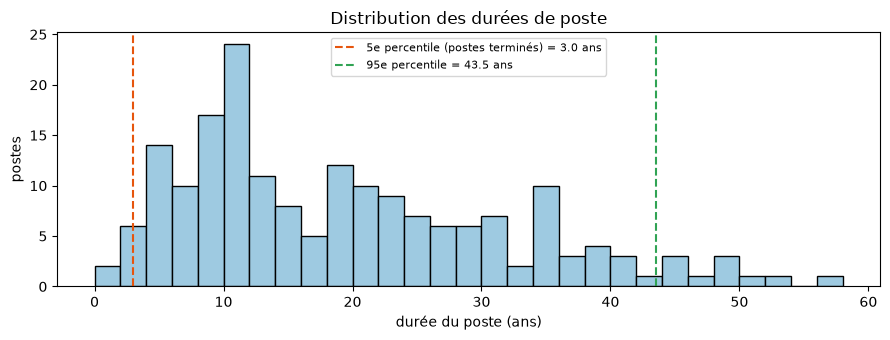

,signal,nom,type,poste,structure,debut,fin,en_cours,duree_ans,birth_min,age_debut
4,durée très longue (≥ P95),Rayan Belen,mandat privé,Chair of Belen Agro-Industries,Belen Agro-Industries,1981-01-01,NaT,True,44.2,1952.0,29.0
8,durée très longue (≥ P95),Bran Grell,mandat privé,Maritime operations executive,Nivren Maritime Logistics,1980-01-01,NaT,True,45.2,1949.0,31.0
19,durée très longue (≥ P95),Zalia Maren,nomination publique,Deputy minister,Avelora Ministry of Strategic Resources,1980-01-01,NaT,True,45.2,1947.0,33.0
11,durée très longue (≥ P95),Leora Kassen,nomination publique,Head of government of Kintara Republic,Office of the Kintara Chancellor,1978-01-01,NaT,True,47.2,1947.0,31.0
2,durée très longue (≥ P95),Celene Varro,mandat privé,Chief executive of Solvane Energy Group,Solvane Energy Group,1977-01-01,NaT,True,48.2,1950.0,27.0
0,durée très longue (≥ P95),Edward Vann,mandat privé,Industrial and shipping adviser,Vann Maritime Advisory,1840-01-01,1888-12-31,False,49.0,1815.0,25.0
1,durée très longue (≥ P95),Emil Warden,mandat privé,Commercial and medical investor,Warden Medical Ventures,1895-01-01,1943-12-31,False,49.0,1871.0,24.0
12,durée très longue (≥ P95),Mirek Talven,nomination publique,Regional governor in the Tembara Commonwealth,Tembara Coastal Administration,1974-01-01,NaT,True,51.2,1942.0,32.0
3,durée très longue (≥ P95),Oskar Nivren,mandat privé,Executive chair of Nivren Maritime Logistics,Nivren Maritime Logistics,1973-01-01,NaT,True,52.2,1946.0,27.0
14,durée très longue (≥ P95),Elira Vaun,nomination publique,Retired political intermediary and former council president,Avelora Council of State,1965-01-01,2021-09-18,False,56.7,1935.0,30.0


In [34]:
valid_durations = posts[~posts["date_incoherente"]]
finished_durations = valid_durations[~valid_durations["en_cours"]]["duree_ans"]
SHORT = finished_durations.quantile(0.05)
LONG = valid_durations["duree_ans"].quantile(0.95)
print(f"Durées des postes terminés : médiane {finished_durations.median():.1f} ans, "
      f"5e percentile {SHORT:.1f} ans ({len(finished_durations)} postes)")
print(f"Durées de tous les postes : 95e percentile {LONG:.1f} ans")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(valid_durations["duree_ans"].dropna(), bins=range(0, 60, 2), color="#9ecae1", edgecolor="black")
ax.axvline(SHORT, color="#e6550d", linestyle="--", label=f"5e percentile (postes terminés) = {SHORT:.1f} ans")
ax.axvline(LONG, color="#31a354", linestyle="--", label=f"95e percentile = {LONG:.1f} ans")
ax.set_xlabel("durée du poste (ans)")
ax.set_ylabel("postes")
ax.set_title("Distribution des durées de poste")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for r in posts.itertuples():
    # un meme poste peut declencher plusieurs signaux
    found = []
    if (not r.en_cours and r.duree_ans <= SHORT):
        found.append("départ rapide (≤ P5)")
    if (r.motif_depart in ["deceased", "retired"]):
        found.append("départ : " + r.motif_depart)
    if (r.duree_ans >= LONG):
        found.append("durée très longue (≥ P95)")
    if (r.age_debut < 18):
        found.append("âge au début < 18")
    for signal in found:
        rows.append({
            "signal": signal, "nom": r.nom, "type": r.type, "poste": r.poste, "structure": r.structure,
            "debut": r.debut, "fin": r.fin, "en_cours": r.en_cours, "duree_ans": r.duree_ans,
            "birth_min": r.birth_min, "age_debut": r.age_debut
        })
signals = pd.DataFrame(rows)
signals.sort_values(["signal", "duree_ans"])

In [35]:
transitions = []
finished = valid[valid["fin"].notna()]
for person_id, group in finished.groupby("person_id"):
    for a in group.itertuples():
        # chercher un poste de l'autre type qui commence au plus 2 ans apres la fin
        for b in valid[valid["person_id"] == person_id].itertuples():
            if (b.type == a.type):
                continue
            too_early = b.debut < a.fin - pd.DateOffset(days=31)
            too_late = b.debut > a.fin + pd.DateOffset(years=2)
            if (not too_early and not too_late):
                transitions.append({
                    "nom": a.nom,
                    "quitte": f"{a.poste} @ {a.structure}",
                    "fin": a.fin.date(),
                    "rejoint": f"{b.poste} @ {b.structure}",
                    "debut": b.debut.date(),
                    "sens": f"{a.type} → {b.type}"
                })
pd.DataFrame(transitions)

,nom,quitte,fin,rejoint,debut,sens
0,Rayan Belen,Agricultural programme director @ Avelora Agricultural R...,1992-12-31,Managing director @ Belen Agro-Industries,1993-01-01,nomination publique → mandat privé
1,Liora Maren,Deputy director @ Pollinator Justice Network,2016-12-31,Wildlife programme officer @ Kintara Cave and Pollinator...,2017-01-01,mandat privé → nomination publique
2,Nora Yorin,Programme manager @ Orison Medical Audit Board,2018-12-31,Policy consultant @ Vale Strategy Collective,2019-01-01,nomination publique → mandat privé
3,Yorin Serin,Deputy director @ Avelora Ministry of Strategic Resources,1989-12-31,Investigative reporter @ Lantern Investigative Bureau,1990-01-01,nomination publique → mandat privé
4,Faris Quell,Regional adviser @ Avelora Agricultural Resilience Agency,2007-12-31,Agricultural operations director @ Belen Agro-Industries,2008-01-01,nomination publique → mandat privé
5,Petra Grell,Operations manager @ Pollinator Justice Network,2004-12-31,Wildlife programme officer @ Kintara Cave and Pollinator...,2005-01-01,mandat privé → nomination publique
6,Doran Maren,Deputy director @ Earth Ledger Project,1993-12-31,Biodiversity programme officer @ Tembara Biodiversity Se...,1994-01-01,mandat privé → nomination publique
7,Miran Lorin,Regional adviser @ Orison Medical Audit Board,2011-12-31,Policy consultant @ Vale Strategy Collective,2012-01-01,nomination publique → mandat privé
8,Xara Orell,Regional adviser @ Avelora Ministry of Strategic Resources,2011-12-31,Investigative reporter @ Lantern Investigative Bureau,2012-01-01,nomination publique → mandat privé
9,Orin Kassen,Programme manager @ Avelora Agricultural Resilience Agency,2007-12-31,Agricultural operations director @ Belen Agro-Industries,2008-01-01,nomination publique → mandat privé


### 4.4 Chronologie des mandats et des licences

Frise de 5 personnes choisies pour ce qu'elles illustrent :

- **Rayan Belen** : cumul public ↔ privé ;
- **Oskar Nivren** : cumul entre deux transporteurs ;
- **Celene Varro** : cumul entre une entreprise et le conseil industriel ;
- **Dr. Lysa Quen** : auditrice publique et médecin licenciée ;
- **Elira Vaun** : 56 ans au Conseil d'État.

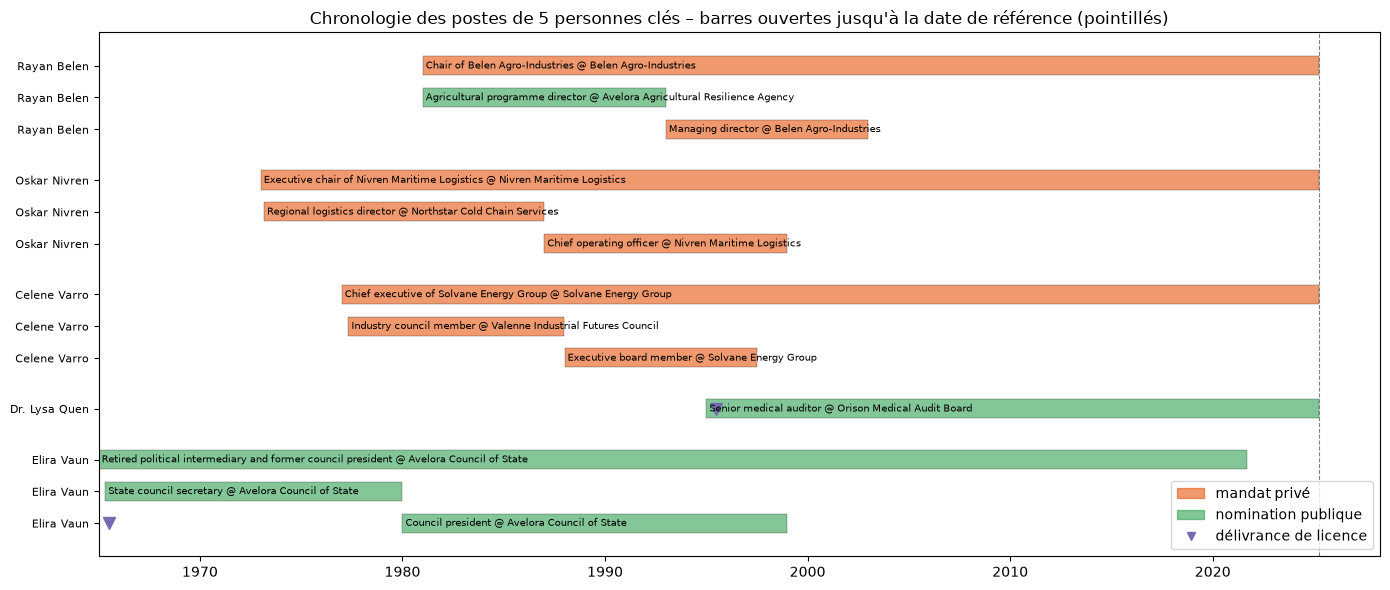

In [36]:
licence_person = []
for license_number in professionals["license_number"]:
    licence_person.append(pid[("licensed_professionals", license_number)])
licences = professionals.copy()
licences["person_id"] = licence_person

FOCUS = ["Rayan Belen", "Oskar Nivren", "Celene Varro", "Dr. Lysa Quen", "Elira Vaun"]
focus_ids = []
for name in FOCUS:
    focus_ids.append(persons_name[persons_name == name].index[0])

fig, ax = plt.subplots(figsize=(14, 6))
colors = {"mandat privé": "#e6550d", "nomination publique": "#31a354"}
y = 0
ticks = []
tick_labels = []
for person_id in focus_ids:
    person_posts = posts[(posts["person_id"] == person_id) & ~posts["date_incoherente"]].sort_values("debut")
    # une ligne par poste, regroupees par personne
    for r in person_posts.itertuples():
        duration = (r.fin_effective - r.debut).days
        ax.barh(y, duration, left=r.debut, height=0.6, color=colors[r.type], alpha=0.6,
                edgecolor="black", linewidth=0.3)
        ax.text(r.debut, y, f" {r.poste} @ {r.structure}", va="center", fontsize=7)
        ticks.append(y)
        tick_labels.append(persons_name[person_id])
        y += 1
    for r in licences[licences["person_id"] == person_id].itertuples():
        ax.plot(r.license_issue_date, y - 1, marker="v", color="#756bb1", markersize=9)
    # espace entre deux personnes
    y += 0.6

ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels, fontsize=8)
ax.invert_yaxis()
ax.axvline(REF_DATE, color="grey", linestyle="--", linewidth=0.8)
handles = []
for kind in colors:
    handles.append(plt.Rectangle((0, 0), 1, 1, color=colors[kind], alpha=0.6))
handles.append(plt.Line2D([], [], marker="v", color="#756bb1", linestyle=""))
ax.legend(handles, ["mandat privé", "nomination publique", "délivrance de licence"], loc="lower right")
ax.set_title("Chronologie des postes de 5 personnes clés – barres ouvertes jusqu'à la date de référence (pointillés)")
plt.tight_layout()
plt.savefig(OUT / "chronologie_mandats.png", dpi=150)
plt.show()

**Résultats sur les nominations et les départs.**

1. **Cumuls** : 56 personnes ont au moins 2 postes et 24 apparaissent à la fois dans le privé et dans le public. Les seuls cumuls simultanés entre structures différentes concernent des dirigeants historiques :
   - **Rayan Belen**, président de Belen Agro-Industries depuis 1981 et en même temps directeur du programme agricole de l'Avelora Agricultural Resilience Agency (1981-1992). C'est le seul chevauchement public ↔ privé (12 ans), donc un risque clair de conflit d'intérêts ;
   - **Celene Varro** (Solvane + conseil industriel) et **Adrienne Solva** (Ardena + Whitehaven) ;
   - **Oskar Nivren**, président de Nivren Maritime Logistics et en même temps directeur régional d'un autre transporteur, Northstar Cold Chain Services (1973-1986).
2. **Allers-retours public ↔ privé** : 19 transitions se font **du jour au lendemain** (fin au 31/12, début au 01/01). Elles forment des **filières régulières** :
   - Avelora Agricultural Resilience Agency → Belen Agro-Industries (4 personnes) ;
   - Orison Medical Audit Board → Vale Strategy Collective (4) ;
   - Avelora Ministry of Strategic Resources → Lantern Investigative Bureau (3) ;
   - Pollinator Justice Network → Kintara Cave and Pollinator Authority (4) ;
   - Earth Ledger Project → Tembara Biodiversity Service (3) ;
   - Asterion Clinical Institute → Tembara Coastal Administration (Sena Grell).

   Le régulateur agricole alimente l'agro-industriel qu'il encadre, et l'auditeur médical alimente le cabinet de conseil de Jacob Vale.
3. **Mandats très longs** : le 95ᵉ percentile des durées est de 43,5 ans. Les postes qui l'atteignent sont presque tous ceux de dirigeants politiques ou d'entreprise **sans date de fin** :
   - côté public, **Mirek Talven** (gouverneur depuis 1974), **Leora Kassen** (cheffe de gouvernement depuis 1978) et **Zalia Maren** (vice-ministre depuis 1980) ; **Elira Vaun** est restée au Conseil d'État de 1965 à son décès en 2021 ;
   - côté privé, Oskar Nivren, Celene Varro, Rayan Belen et Bran Grell dirigent leur entreprise depuis 1973-1981.

   Les deux seuls postes terminés de cette liste sont ceux d'**Edward Vann** et d'**Emil Warden** (49 ans chacun, au XIXe et au début du XXe siècle), qui réapparaissent au §7.
4. **Départs rapides** : le 5ᵉ percentile des durées des postes terminés est de 3 ans (médiane : 10 ans). 7 postes sont à ce niveau ou en dessous. Le plus court est celui de Miran Lorin (1 an à l'Orison Medical Audit Board, 2011), suivi d'un départ immédiat vers Vale Strategy Collective. Les 7 personnes avaient **24 ans** au début de ce poste et en ont pris un autre juste après. Ces départs rapides ressemblent donc à des **premiers postes** courts, pas à des départs anormaux.
5. **Dates incohérentes (9 dépôts)** : chaque fois, la cessation précède la nomination (de 1 jour à 1 an). Pour 3 d'entre eux (Liora Corda, Jalen Quorin, Petra Koral : *Regional adviser* chez Asterion), la personne occupe déjà, ou commence la même année, une nomination publique de *Regional administrative director* à la Tembara Coastal Administration. Il pourrait donc s'agir de mandats déclarés mais jamais exercés. C'est une hypothèse non vérifiable ici.

### 4.5 Plausibilité des licences

`license_expiry_date` étant toujours vide, on contrôle la validité par l'**ancienneté** : une licence délivrée il y a plus de 60 ans et toujours `active`, ou détenue par une personne qui aurait plus de 100 ans, est invraisemblable. On croise avec l'année de naissance connue côté mandats et on signale les licences délivrées après la date de référence.

In [37]:
lic = licences.copy()
lic["anciennete_ans"] = ((REF_DATE - lic["license_issue_date"]).dt.days / 365.25).round(0)
lic["birth_min"] = lic["person_id"].map(persons["birth_min"])
lic["age_ref"] = REF_DATE.year - lic["birth_min"]
lic["apres_ref"] = lic["license_issue_date"] > REF_DATE

fac_start = clean["facilities"].set_index("facility_license_number")["license_start"]
lic["etab_ouvert_apres_licence"] = lic["primary_facility_license"].map(fac_start) > lic["license_issue_date"]
print("Licences rattachées à un établissement principal ouvert après leur délivrance :",
      int(lic["etab_ouvert_apres_licence"].sum()), "/", int(lic["primary_facility_license"].notna().sum()))

too_old = lic["anciennete_ans"] > 60
too_aged = lic["age_ref"] > 100
suspicious_lic = lic[too_old | too_aged | lic["apres_ref"]]
suspicious_lic[["license_number", "professional_name", "profession", "specialty", "license_issue_date",
                "license_status", "primary_facility_license", "etab_ouvert_apres_licence",
                "anciennete_ans", "birth_min", "age_ref", "apres_ref"]]

Licences rattachées à un établissement principal ouvert après leur délivrance : 22 / 27


,license_number,professional_name,profession,specialty,license_issue_date,license_status,primary_facility_license,etab_ouvert_apres_licence,anciennete_ans,birth_min,age_ref,apres_ref
0,LIC-VLN-MED-1001,Emil Warden,physician,cardiology,1895-07-01,active,FAC-VLN-101,True,130.0,1871.0,154.0,False
5,LIC-VLN-MED-1006,Farah Havel,physician,occupational medicine,2026-07-01,active,FAC-AVL-201,False,-1.0,1994.0,31.0,True
6,LIC-KNT-RES-1007,J. Varlan,research professional,ecological analytics,1886-07-01,active,FAC-AVL-301,True,139.0,1862.0,163.0,False
7,LIC-AVL-RES-1008,Jonah Bell,research professional,public policy research,1924-07-01,active,FAC-AVL-301,True,101.0,1900.0,125.0,False


Toutes les licences restent `active`, y compris celles de personnes nées au XIXe siècle : **J. Varlan** (délivrée en 1886, il aurait 163 ans), **Jonah Bell** (1924, 125 ans) et **Emil Warden** (1895, 154 ans). À l'inverse, la licence de **Farah Havel** est datée du 2026-07-01, après la date de référence. Le registre ne gère donc pas la fin de validité des licences. Le contrôle suivant (§5) vérifie si ces licences sont réellement utilisées.

22 des 27 licences sont rattachées à un établissement ouvert *après* leur délivrance. On l'interprète comme une affectation **actuelle** (mise à jour du rattachement) plutôt que comme une anomalie.

## 5. Relier les registres à la santé

Jointures par clé exacte (pas de rapprochement par nom) :

- `clinical_encounters.attending_license_number` → `licensed_professionals.license_number`
- `clinical_encounters.facility_license_number` → `licensed_facilities.facility_license_number`
- idem pour `clinical_procedures` (`performing_license_number`, `performing_facility_license`).

Contrôle préalable : toutes les clés étrangères doivent exister dans le registre, et une jointure *many-to-one* ne doit pas multiplier les lignes.

In [38]:
enc = clean["encounters"]
proc = clean["procedures"]

# chaque cle etrangere doit exister dans le registre correspondant
checks = [
    ("encounters.attending_license_number", enc["attending_license_number"], professionals["license_number"]),
    ("encounters.facility_license_number", enc["facility_license_number"], facilities["facility_license_number"]),
    ("procedures.performing_license_number", proc["performing_license_number"], professionals["license_number"]),
    ("procedures.performing_facility_license", proc["performing_facility_license"], facilities["facility_license_number"]),
]
rows = []
for label, keys, reference in checks:
    found = keys.isin(reference)
    rows.append({"jointure": label, "clés trouvées": int(found.sum()), "clés absentes": int((~found).sum())})
pd.DataFrame(rows).set_index("jointure")

,clés trouvées,clés absentes
jointure,,
encounters.attending_license_number,1069,0
encounters.facility_license_number,1069,0
procedures.performing_license_number,311,0
procedures.performing_facility_license,311,0


In [39]:
# many_to_one : une licence par ligne cote registre, donc pas de lignes en plus
enc_p = enc.merge(professionals, left_on="attending_license_number", right_on="license_number",
                  how="left", validate="many_to_one")
assert len(enc_p) == len(enc)
proc_p = proc.merge(professionals, left_on="performing_license_number", right_on="license_number",
                    how="left", validate="many_to_one")
assert len(proc_p) == len(proc)

rows = []
for license_number, group in enc_p.groupby("attending_license_number"):
    secret = group["confidentiality_class"].isin(["confidential", "restricted"])
    # rencontres signees avant meme que la licence existe
    before_licence = group["encounter_start"] < group["license_issue_date"]
    rows.append({
        "attending_license_number": license_number,
        "praticien": group["professional_name"].iloc[0],
        "specialite": group["specialty"].iloc[0],
        "licence_delivree": group["license_issue_date"].iloc[0],
        "etab_principal": group["primary_facility_license"].iloc[0],
        "rencontres": len(group),
        "patients": group["patient_number"].nunique(),
        "premiere": group["encounter_start"].min(),
        "derniere": group["encounter_start"].max(),
        "part_confidentiel_restreint": round(secret.mean(), 2),
        "rencontres_avant_licence": int(before_licence.sum())
    })
vol = pd.DataFrame(rows).set_index("attending_license_number")

vol["procedures"] = proc_p.groupby("performing_license_number").size()
mrp = proc_p[proc_p["procedure_code"] == "MRP-42"]
vol["MRP-42"] = mrp.groupby("performing_license_number").size()
vol["MRP-42"] = vol["MRP-42"].fillna(0).astype(int)

births = []
for license_number in vol.index:
    person_id = pid[("licensed_professionals", license_number)]
    births.append(persons.loc[person_id, "birth_min"])
vol["birth_min"] = births
vol["age_derniere_rencontre"] = vol["derniere"].dt.year - vol["birth_min"]
vol = vol[["praticien", "specialite", "licence_delivree", "etab_principal", "rencontres", "patients",
           "premiere", "derniere", "part_confidentiel_restreint", "procedures", "MRP-42",
           "rencontres_avant_licence", "birth_min", "age_derniere_rencontre"]]
vol.sort_values("rencontres", ascending=False)

,praticien,specialite,licence_delivree,etab_principal,rencontres,patients,premiere,derniere,part_confidentiel_restreint,procedures,MRP-42,rencontres_avant_licence,birth_min,age_derniere_rencontre
attending_license_number,,,,,,,,,,,,,,
LIC-VLN-MED-1002,Dr. Naima Orrel,preventive medicine,2002-07-01,FAC-VLN-101,162,112,2014-07-18 08:30:00,2025-06-20 14:15:00,0.56,67,36,0,1978.0,47.0
LIC-VLN-MED-1001,Emil Warden,cardiology,1895-07-01,FAC-VLN-101,147,118,2015-09-21 09:15:00,2025-06-20 13:15:00,0.51,35,1,0,1871.0,154.0
LIC-VLN-RES-1016,Daria Zaven,general medicine,1990-07-01,FAC-VLN-101,140,112,2017-01-26 09:15:00,2026-01-11 14:15:00,0.43,44,3,0,1950.0,76.0
LIC-VLN-MED-1006,Farah Havel,occupational medicine,2026-07-01,FAC-AVL-201,136,110,2014-02-18 09:15:00,2025-09-11 14:15:00,0.42,33,4,136,1994.0,31.0
LIC-VLN-MED-1003,Dr. Corin Hale,cardiac imaging,2002-07-01,FAC-AVL-201,122,99,2017-02-05 09:15:00,2025-06-21 14:15:00,0.44,31,1,0,1974.0,51.0
LIC-VLN-MED-1004,Dr. Lysa Quen,medical audit,1995-07-01,FAC-VLN-101,121,98,2014-08-15 10:15:00,2025-06-20 13:15:00,0.44,32,3,0,1968.0,57.0
LIC-VLN-RES-1044,Ravin Palen,clinical physiology,1995-07-01,FAC-VLN-101,121,99,2016-03-22 10:15:00,2025-06-20 13:15:00,0.36,31,2,0,1963.0,62.0
LIC-VLN-MED-1005,Faris Uren,cardiology,1986-07-01,FAC-VLN-101,120,96,2015-04-13 09:15:00,2025-06-20 13:15:00,0.44,38,0,0,1961.0,64.0


In [40]:
in_encounters = professionals["license_number"].isin(enc["attending_license_number"])
in_procedures = professionals["license_number"].isin(proc["performing_license_number"])
health_people = in_encounters | in_procedures
print(f"Professionnels licenciés présents dans les données de santé : {health_people.sum()} / {len(professionals)}")
print("Professions :", professionals.loc[health_people, "profession"].value_counts().to_dict())

fac_by_id = facilities.set_index("facility_license_number")
rows = []
for facility, group in enc.groupby("facility_license_number"):
    start = fac_by_id.loc[facility, "license_start"]
    rows.append({
        "facility_license_number": facility,
        "rencontres": len(group),
        "patients": group["patient_number"].nunique(),
        "rencontres_avant_licence": int((group["encounter_start"] < start).sum())
    })
counts = pd.DataFrame(rows).set_index("facility_license_number")
counts["procedures"] = proc.groupby("performing_facility_license").size()

fac_vol = fac_by_id[["facility_name", "facility_category", "operating_organization_registration", "license_start"]]
fac_vol = fac_vol.join(counts[["rencontres", "patients", "procedures", "rencontres_avant_licence"]])
fac_vol["operateur"] = fac_vol["operating_organization_registration"].map(entity_name)
fac_vol

Professionnels licenciés présents dans les données de santé : 8 / 53
Professions : {'physician': 8}


,facility_name,facility_category,operating_organization_registration,license_start,rencontres,patients,procedures,rencontres_avant_licence,operateur
facility_license_number,,,,,,,,,
FAC-VLN-101,Asterion Central Clinical Campus,research_hospital,REG-VLN-01002,2001-02-01,659,150,179,0,Asterion Clinical Institute
FAC-AVL-201,Asterion Avelora Executive Clinic,private_clinic,REG-VLN-01002,2008-05-15,294,64,101,0,Asterion Clinical Institute
FAC-AVL-301,Threshold Earth Avelora Laboratory,research_laboratory,REG-AVL-01007,2012-01-18,116,26,31,0,Threshold Earth Observatory


In [41]:
# les praticiens exercent-ils seulement dans leur etablissement principal declare ?
pd.crosstab(enc_p["professional_name"], enc_p["facility_license_number"], margins=True)

facility_license_number,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101,All
professional_name,,,,
Daria Zaven,31,14,95,140
Dr. Corin Hale,32,9,81,122
Dr. Lysa Quen,32,17,72,121
Dr. Naima Orrel,46,13,103,162
Emil Warden,34,19,94,147
Farah Havel,40,14,82,136
Faris Uren,43,17,60,120
Ravin Palen,36,13,72,121
All,294,116,659,1069


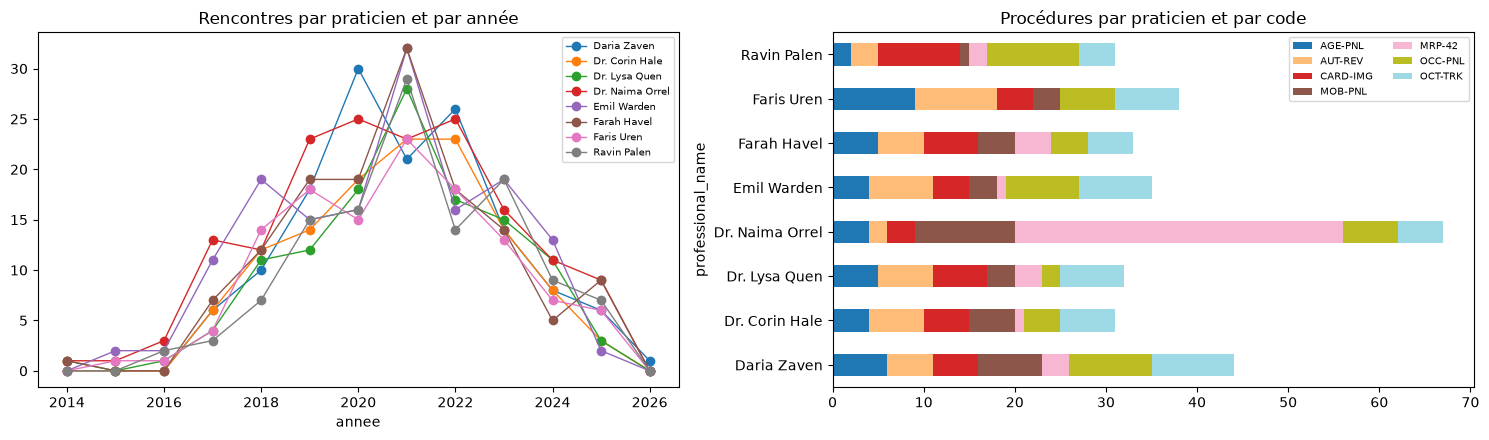

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

enc_p["annee"] = enc_p["encounter_start"].dt.year
yearly = enc_p.pivot_table(index="annee", columns="professional_name", values="encounter_number",
                           aggfunc="count").fillna(0)
yearly.plot(ax=axes[0], marker="o", linewidth=1)
axes[0].set_title("Rencontres par praticien et par année")
axes[0].legend(fontsize=7)

by_code = proc_p.pivot_table(index="professional_name", columns="procedure_code", values="procedure_record_id",
                             aggfunc="count").fillna(0)
by_code.plot(kind="barh", stacked=True, ax=axes[1], colormap="tab20")
axes[1].set_title("Procédures par praticien et par code")
axes[1].legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.savefig(OUT / "volumes_sante.png", dpi=150)
plt.show()

**Résultats santé.**

- Seuls **8 des 53** professionnels licenciés apparaissent dans les données cliniques, tous médecins. Toutes les clés de praticien et d'établissement existent dans le registre, et les jointures ne dupliquent aucune ligne.
- Les volumes sont proches entre praticiens (120 à 162 rencontres). Les rencontres se concentrent à l'Asterion Central Clinical Campus (659). Asterion exploite deux des trois établissements, soit 89 % des rencontres.
- **Licence d'Emil Warden (LIC-VLN-MED-1001)** : délivrée en 1895 à une personne née en 1871. Elle sert pourtant à signer **147 rencontres entre 2015 et 2025**, ce qui supposerait un praticien de 144 à 154 ans. Le fait est établi par une jointure exacte. Son interprétation reste ouverte : réutilisation d'une ancienne licence, usurpation d'identité ou continuité d'identité (§7).
- **Licence de Farah Havel (LIC-VLN-MED-1006)** : délivrée le **2026-07-01**, donc après chacune des 136 rencontres signées (2014-2025). Son mandat chez Asterion commence aussi en 2026. Des actes ont donc été signés sous un numéro de licence qui n'existait pas encore.
- **Dr. Naima Orrel**, directrice de recherche d'Asterion, réalise **36 des 50 actes MRP-42** (« Targeted metabolic resilience administration »), soit 72 %. Les autres praticiens en font entre 0 et 4. Ses rencontres et celles d'Emil Warden ont aussi la plus forte part de dossiers *confidential/restricted* (56 % et 51 %).
- Chaque praticien exerce dans les trois établissements, quel que soit son établissement principal déclaré. Le champ `primary_facility_license` décrit donc un rattachement administratif, pas le lieu réel d'exercice.

## 6. Relier les registres à la logistique

1. **Partenaires** : `erp_business_partners.external_registration_number` → `registered_entities.registration_number` (clé exacte), puis contrôle de cohérence du nom et des dates (un partenaire ne devrait pas être intégré après la dissolution de l'entité).
2. **Partenaires sans clé connue** : rapprochement approché du `partner_name` avec `legal_name`, pour repérer d'éventuelles organisations enregistrées sous une autre clé.
3. **Installations** : `erp_facilities` ↔ `licensed_facilities` (nom normalisé + distance entre coordonnées) et ↔ `registered_entities.registered_address` (une adresse d'organisation qui correspond à une installation logistique).

In [43]:
partners = clean["partners"]
erp_fac = clean["erp_facilities"]

has_key = partners["external_registration_number"].notna()
in_registry = partners["external_registration_number"].isin(entities["registration_number"])
print(f"Partenaires : {len(partners)} | avec numéro d'enregistrement : {has_key.sum()} "
      f"| trouvés dans le registre : {in_registry.sum()}")

# regarder le debut des numeros inconnus pour comprendre leur format
prefixes = {}
for number in partners.loc[has_key & ~in_registry, "external_registration_number"]:
    prefix = number[:9]
    prefixes[prefix] = prefixes.get(prefix, 0) + 1
print("Préfixes des numéros absents du registre :", pd.Series(prefixes).sort_values(ascending=False).to_dict())

with_key = partners[has_key]
pe = with_key.merge(entities, left_on="external_registration_number", right_on="registration_number",
                    how="inner", validate="one_to_one")
pe["meme_nom"] = pe["partner_name"].map(normalize_name) == pe["legal_name"].map(normalize_name)
# une entite dissoute ne devrait pas devenir partenaire apres sa dissolution
dissolved = pe["current_status"] == "dissolved"
pe["integre_apres_dissolution"] = dissolved & (pe["onboarding_date"] > pe["last_filing_date"])
pe["ecart_ans"] = ((pe["onboarding_date"] - pe["last_filing_date"]).dt.days / 365.25).round(0)
print("Noms identiques partenaire/registre :", pe["meme_nom"].all())

table = pe[["partner_code", "partner_name", "partner_role", "risk_class", "partner_status", "onboarding_date",
            "registration_number", "registered_entity_type", "current_status", "last_filing_date",
            "integre_apres_dissolution", "ecart_ans"]]
table.sort_values(["integre_apres_dissolution", "onboarding_date"], ascending=[False, True])

Partenaires : 80 | avec numéro d'enregistrement : 66 | trouvés dans le registre : 24
Préfixes des numéros absents du registre : {'REG-VLN-2': 13, 'REG-TMB-2': 9, 'REG-AVL-2': 8, 'REG-KNT-2': 6, 'REG-NDH-2': 6}
Noms identiques partenaire/registre : True


,partner_code,partner_name,partner_role,risk_class,partner_status,onboarding_date,registration_number,registered_entity_type,current_status,last_filing_date,integre_apres_dissolution,ecart_ans
4,BP-30013,Vann Maritime Advisory,service_partner,standard,inactive,2001-02-01,REG-NDH-01015,consulting_company,dissolved,1891-12-31,True,109.0
19,BP-30059,Bell Conservation Survey,customer,standard,inactive,2004-12-01,REG-AVL-01019,research_institute,dissolved,1966-12-31,True,38.0
7,BP-30022,Varlan Natural History Circle,customer,low,inactive,2008-11-01,REG-KNT-01018,research_institute,dissolved,1920-12-31,True,88.0
9,BP-30038,Vosmere Biotechnics,supplier_customer,standard,inactive,2009-03-01,REG-NDH-01017,biotechnology_company,dissolved,1994-12-31,True,14.0
1,BP-30005,Warden Medical Ventures,service_partner,standard,inactive,2013-06-01,REG-VLN-01016,investment_company,dissolved,1948-12-31,True,64.0
21,BP-30066,Belen Agro-Industries,supplier_customer,standard,active,2000-07-01,REG-KNT-01024,agricultural_company,active,2025-03-31,False,-25.0
6,BP-30021,Asterion Clinical Institute,customer,review,active,2003-10-01,REG-VLN-01002,research_institute,active,2025-03-31,False,-21.0
18,BP-30058,Marot Ecological Policy Office,service_partner,standard,inactive,2004-11-01,REG-VLN-01020,consulting_company,dissolved,2006-12-31,False,-2.0
16,BP-30047,Northstar Cold Chain Services,carrier,elevated,active,2006-12-01,REG-TMB-01003,logistics_company,active,2025-03-31,False,-18.0
20,BP-30062,Solvane Energy Group,customer,elevated,active,2007-03-01,REG-VLN-01021,energy_company,active,2025-03-31,False,-18.0


In [44]:
# partenaires ERP qui n'existent dans aucun registre : sans numero, ou numero inconnu
absent = partners[~in_registry].copy()
reasons = []
for number in absent["external_registration_number"]:
    if (pd.isna(number)):
        reasons.append("aucun numéro d'enregistrement")
    else:
        reasons.append("numéro absent du registre")
absent["motif"] = reasons
absent.to_csv(OUT / "partenaires_absents_registre.csv", index=False)
print(f"Partenaires absents du registre : {len(absent)} / {len(partners)} "
      f"(taux de correspondance : {100 * in_registry.mean():.0f} %)")
print(pd.crosstab(absent["motif"], absent["partner_role"], margins=True).to_string())
absent[["partner_code", "partner_name", "partner_role", "external_registration_number", "billing_region",
        "partner_status", "risk_class", "onboarding_date", "motif"]].sort_values(["motif", "partner_code"])

Partenaires absents du registre : 56 / 80 (taux de correspondance : 30 %)
partner_role                   Supplier  carrier  customer  service_partner  supplier  supplier_customer  All
motif                                                                                                        
aucun numéro d'enregistrement         0        0        14                0         0                  0   14
numéro absent du registre             1        6         9                9        13                  4   42
All                                   1        6        23                9        13                  4   56


,partner_code,partner_name,partner_role,external_registration_number,billing_region,partner_status,risk_class,onboarding_date,motif
5,BP-30006,Avelora Food Standards Office,customer,NaN,Avelora Federation,active,standard,2013-07-01,aucun numéro d'enregistrement
9,BP-30010,Tembara Coastal Administration,customer,NaN,Tembara Commonwealth,active,low,1998-11-01,aucun numéro d'enregistrement
15,BP-30016,Kintara Cave and Pollinator Authority,customer,NaN,Kintara Republic,active,low,2009-05-01,aucun numéro d'enregistrement
18,BP-30019,Orison Medical Audit Board,customer,NaN,Valenne Republic,active,review,2000-08-01,aucun numéro d'enregistrement
26,BP-30027,Kintara Emergency Response Office,customer,NaN,Kintara Republic,active,low,2010-04-01,aucun numéro d'enregistrement
35,BP-30036,Office of the Kintara Chancellor,customer,NaN,Kintara Republic,active,low,2001-01-01,aucun numéro d'enregistrement
44,BP-30045,Tembara Biodiversity Service,customer,NaN,Tembara Commonwealth,active,review,2003-10-01,aucun numéro d'enregistrement
50,BP-30051,Tembara Customs Coordination Unit,customer,NaN,Tembara Commonwealth,active,review,2010-04-01,aucun numéro d'enregistrement
60,BP-30061,Kintara Rural Transport Board,customer,NaN,Kintara Republic,active,low,2016-02-01,aucun numéro d'enregistrement
62,BP-30063,Nordhaven Maritime Safety Agency,customer,NaN,Nordhaven Union,active,review,2007-04-01,aucun numéro d'enregistrement


In [45]:
pd.crosstab(pe["current_status"], pe["risk_class"], margins=True)

risk_class,elevated,low,review,standard,All
current_status,,,,,
active,5,2,4,7,18
dissolved,0,1,0,5,6
All,5,3,4,12,24


In [46]:
unmatched = partners[~in_registry]
fuzzy = []
for r in unmatched.itertuples():
    for e in entities.itertuples():
        score = fuzz.token_sort_ratio(normalize_name(r.partner_name), normalize_name(e.legal_name))
        if (score >= 70):
            fuzzy.append({
                "partner_code": r.partner_code,
                "partner_name": r.partner_name,
                "external_registration_number": r.external_registration_number,
                "legal_name": e.legal_name,
                "registration_number": e.registration_number,
                "score": round(score, 1)
            })
print(f"Partenaires hors registre rapprochés par nom (score ≥ 70) : {len(fuzzy)}")
pd.DataFrame(fuzzy)

Partenaires hors registre rapprochés par nom (score ≥ 70) : 0


""


In [47]:
def haversine_km(lat1, lon1, lat2, lon2):
    """
    Distance en km entre deux points donnes en latitude/longitude.
    """
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    # 6371 km = rayon moyen de la Terre
    return 6371 * 2 * np.arcsin(np.sqrt(a))


partner_reg = partners.set_index("partner_code")["external_registration_number"]
rows = []
for f in erp_fac.itertuples():
    for lf in facilities.itertuples():
        score = fuzz.token_sort_ratio(normalize_name(f.facility_name), normalize_name(lf.facility_name))
        if (score >= 80):
            distance = haversine_km(float(f.latitude), float(f.longitude), float(lf.latitude), float(lf.longitude))
            rows.append({
                "facility_code": f.facility_code,
                "erp_name": f.facility_name,
                "erp_category": f.facility_category,
                "facility_license_number": lf.facility_license_number,
                "registry_name": lf.facility_name,
                "score_nom": round(score, 1),
                "distance_km": round(distance, 1),
                # operateur cote ERP, traduit en numero du registre
                "operateur_erp → reg": partner_reg.get(f.operating_partner_code),
                "operateur_registre": lf.operating_organization_registration
            })
fac_match = pd.DataFrame(rows)
fac_match["meme_operateur"] = fac_match["operateur_erp → reg"] == fac_match["operateur_registre"]
fac_match

,facility_code,erp_name,erp_category,facility_license_number,registry_name,score_nom,distance_km,operateur_erp → reg,operateur_registre,meme_operateur
0,FCL-1010,Asterion Central Clinical Campus,laboratory_delivery_point,FAC-VLN-101,Asterion Central Clinical Campus,100.0,0.0,REG-VLN-01002,REG-VLN-01002,True
1,FCL-1007,Asterion Avelora Executive Clinic,clinical_delivery_point,FAC-AVL-201,Asterion Avelora Executive Clinic,100.0,0.0,REG-VLN-01002,REG-VLN-01002,True
2,FCL-1015,Threshold Earth Avelora Laboratory,laboratory_delivery_point,FAC-AVL-301,Threshold Earth Avelora Laboratory,100.0,0.0,REG-AVL-01007,REG-AVL-01007,True


In [48]:
# une adresse enregistree qui porte le nom d'une installation logistique
addr = []
for e in entities.itertuples():
    for h in erp_fac.itertuples():
        if (normalize_name(h.facility_name) != normalize_name(e.registered_address)):
            continue
        operator_reg = partner_reg.get(h.operating_partner_code)
        operator = entity_name.get(operator_reg, h.operating_partner_code)
        addr.append({
            "organisation": e.legal_name,
            "registration_number": e.registration_number,
            "adresse_enregistree": e.registered_address,
            "installation_erp": h.facility_code,
            "categorie": h.facility_category,
            "operateur_installation": operator,
            # l'installation est exploitee par une autre organisation
            "domiciliation_chez_un_tiers": operator_reg != e.registration_number
        })
pd.DataFrame(addr)

,organisation,registration_number,adresse_enregistree,installation_erp,categorie,operateur_installation,domiciliation_chez_un_tiers
0,Meridian BioLogistics,REG-VLN-01001,Meridian Valenne Headquarters,FCL-1011,office,Meridian BioLogistics,False
1,Asterion Clinical Institute,REG-VLN-01002,Asterion Central Clinical Campus,FCL-1010,laboratory_delivery_point,Asterion Clinical Institute,False
2,Northstar Cold Chain Services,REG-TMB-01003,Northstar Tembara Cold-Chain Hub,FCL-1016,warehouse,Northstar Cold Chain Services,False
3,Whitehaven Strategic Holdings,REG-VLN-01004,Meridian Valenne Headquarters,FCL-1011,office,Meridian BioLogistics,True
4,Vale Strategy Collective,REG-VLN-01006,Vale Strategy Valenne Office,FCL-1029,office,Vale Strategy Collective,False
5,Threshold Earth Observatory,REG-AVL-01007,Threshold Earth Avelora Laboratory,FCL-1015,laboratory_delivery_point,Threshold Earth Observatory,False


**Résultats logistique.**

- **24 des 80 partenaires** ERP sont des organisations du registre, avec une clé exacte et un nom identique. Les **56 autres** sont absents de tout registre ; leur liste est exportée dans `partenaires_absents_registre.csv` :
  - **42** ont un numéro d'un autre format (`REG-xxx-2xxxx`) qui n'existe pas dans le registre fourni (fournisseurs, transporteurs, prestataires, clients) ;
  - **14** n'ont aucun numéro : ce sont tous des clients publics (ministères, agences, Orison Medical Audit Board, Conseil d'État…), qui n'ont pas à figurer au registre des entreprises.

  Le rapprochement par nom (`token_sort_ratio` ≥ 70) ne trouve **aucun** nom proche dans le registre : ces partenaires ne sont pas des organisations du registre mal saisies.
- **5 organisations dissoutes ont été intégrées comme partenaires après leur dissolution** : Vann Maritime Advisory (dissoute en 1891, intégrée en 2001), Varlan Natural History Circle (1920 → 2008), Bell Conservation Survey (1966 → 2004), Warden Medical Ventures (1948 → 2013), Vosmere Biotechnics (1994 → 2009). Elles appartiennent toutes aux deux chaînes du §7. La sixième entité dissoute, Marot Ecological Policy Office, a été intégrée en 2004, deux ans avant sa dissolution. Une entité dissoute ne devrait pas pouvoir devenir fournisseur ou client : ces fiches ressemblent à des **coquilles** réactivées dans l'ERP (toutes sont aujourd'hui `inactive`).
- Les trois établissements de santé agréés existent dans l'ERP comme **points de livraison clinique ou de laboratoire** (même nom, distance de 0 km, même opérateur). Ils peuvent donc recevoir des envois de la chaîne logistique ; le détail des flux (expéditeurs, contenus) relève du volet logistique (développeur 5).
- **Whitehaven Strategic Holdings** (société d'investissement) a pour adresse enregistrée *Meridian Valenne Headquarters*, un bureau exploité par Meridian BioLogistics : la holding est **domiciliée chez Meridian**.

## 7. Liens étayés et liens incertains

Cette partie confronte les résultats précédents pour distinguer ce qui est **démontré par les clés** de ce qui reste une **hypothèse**.

### 7.1 Successions d'organisations

Les entités dissoutes sont comparées aux entités enregistrées **0 à 5 ans** après leur dernier dépôt. Pour chaque entité, on retient comme **fondateur présumé** le déclarant dont la date de nomination est la plus proche de la date d'enregistrement (le mandat le plus ancien ne convient pas : beaucoup de mandats sont antérieurs à l'enregistrement, cf. §1).

In [49]:
# fondateur presume : le declarant nomme le plus pres de la date d'enregistrement
founders = {}
for r in officers.itertuples():
    registration = reg_dates.loc[r.registration_number, "registration_date"]
    gap = abs(r.appointment_date - registration)
    if (r.registration_number not in founders or gap < founders[r.registration_number][0]):
        founders[r.registration_number] = (gap, r)

rows = []
for registration_number in founders:
    r = founders[registration_number][1]
    rows.append({
        "registration_number": registration_number,
        "filing_id": r.filing_id,
        "full_name": r.full_name,
        "birth_year_or_age_band": r.birth_year_or_age_band,
        "role_title": r.role_title,
        "appointment_date": r.appointment_date,
        "cessation_date": r.cessation_date
    })
first_officer = pd.DataFrame(rows).set_index("registration_number")
ent = entities.join(first_officer, on="registration_number")

succ = []
for d in ent[ent["current_status"] == "dissolved"].itertuples():
    for n in ent.itertuples():
        # entite creee dans les 5 ans qui suivent la dissolution
        gap_years = n.registration_date - d.last_filing_date
        if (gap_years < pd.Timedelta(0) or n.registration_date > d.last_filing_date + pd.DateOffset(years=5)):
            continue
        succ.append({
            "dissoute": d.legal_name,
            "fin": d.last_filing_date.year,
            "activite_1": d.declared_activity,
            "dirigeant_1": f"{d.full_name} ({d.birth_year_or_age_band})",
            "suivante": n.legal_name,
            "creation": n.registration_date.year,
            "activite_2": n.declared_activity,
            "dirigeant_2": f"{n.full_name} ({n.birth_year_or_age_band})",
            "ecart_ans": n.registration_date.year - d.last_filing_date.year
        })
succession = pd.DataFrame(succ)
succession

,dissoute,fin,activite_1,dirigeant_1,suivante,creation,activite_2,dirigeant_2,ecart_ans
0,Vann Maritime Advisory,1891,Industrial and shipping advisory practice,Edward Vann (1815),Warden Medical Ventures,1894,Commercial and medical investment partnership,Emil Warden (1871),3
1,Warden Medical Ventures,1948,Commercial and medical investment partnership,Emil Warden (1871),Vosmere Biotechnics,1951,Biotechnology and transport company,Adrian Vosmere (1920–1929),3
2,Vosmere Biotechnics,1994,Biotechnology and transport company,Adrian Vosmere (1920–1929),Meridian BioLogistics,1996,International biological and cold-chain logistics,Dr. Elias Voss (1961),2
3,Varlan Natural History Circle,1920,Natural-history correspondence society,J. Varlan (1862),Bell Conservation Survey,1923,Regional conservation survey,Jonah Bell (1900),3
4,Bell Conservation Survey,1966,Regional conservation survey,Jonah Bell (1900),Marot Ecological Policy Office,1969,Environmental-policy advisory office,Julien Marot (1940–1949),3
5,Bell Conservation Survey,1966,Regional conservation survey,Jonah Bell (1900),Nivren Maritime Logistics,1969,Commercial maritime logistics company,Oskar Nivren (1946),3
6,Marot Ecological Policy Office,2006,Environmental-policy advisory office,Julien Marot (1940–1949),Vale Strategy Collective,2008,Climate and social-policy consultancy,Jacob Vale (1971),2
7,Marot Ecological Policy Office,2006,Environmental-policy advisory office,Julien Marot (1940–1949),Threshold Earth Observatory,2011,Environmental research organization,Selene Aras (1985),5


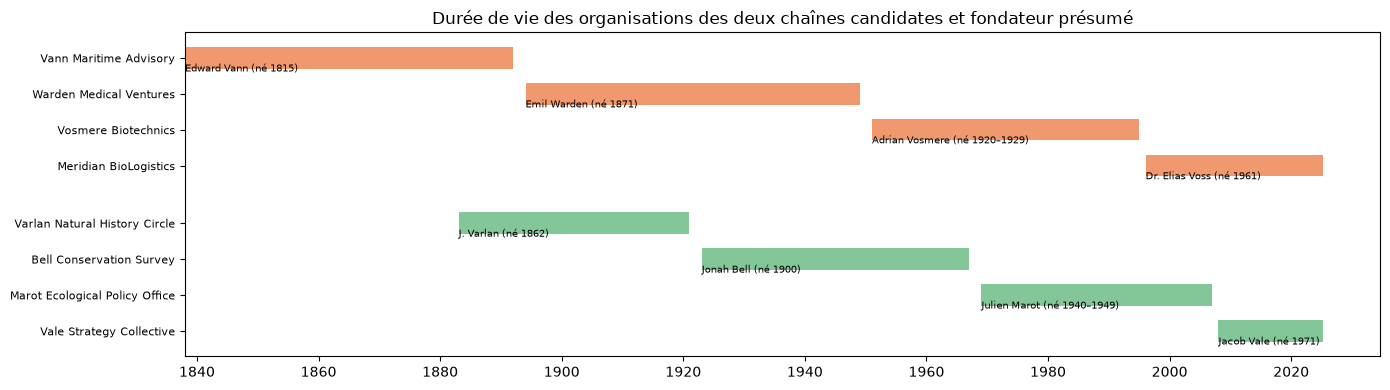

In [50]:
CHAINS = {
    "chaîne logistique / médicale": ["REG-NDH-01015", "REG-VLN-01016", "REG-NDH-01017", "REG-VLN-01001"],
    "chaîne écologie / politique": ["REG-KNT-01018", "REG-AVL-01019", "REG-VLN-01020", "REG-VLN-01006"],
}
ent_by_id = ent.set_index("registration_number")

fig, ax = plt.subplots(figsize=(14, 4))
y = 0
ticks = []
labels = []
for chain in CHAINS:
    color = "#31a354"
    if ("logistique" in chain):
        color = "#e6550d"
    for reg in CHAINS[chain]:
        e = ent_by_id.loc[reg]
        # une entite encore active va jusqu'a la date de reference
        end = REF_DATE
        if (e.current_status == "dissolved"):
            end = e.last_filing_date
        ax.barh(y, (end - e.registration_date).days, left=e.registration_date, height=0.6, color=color, alpha=0.6)
        ax.text(e.registration_date, y + 0.38, f"{e.full_name} (né {e.birth_year_or_age_band})", fontsize=7)
        ticks.append(y)
        labels.append(e.legal_name)
        y += 1
    # petit espace entre les deux chaines
    y += 0.6
ax.set_yticks(ticks)
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_title("Durée de vie des organisations des deux chaînes candidates et fondateur présumé")
plt.tight_layout()
plt.savefig(OUT / "chaines_organisations.png", dpi=150)
plt.show()

In [51]:
lic_by_person = lic.set_index("person_id")
pe_by_reg = pe.set_index("registration_number")

rows = []
for chain in CHAINS:
    for reg in CHAINS[chain]:
        f = first_officer.loc[reg]
        person_id = pid[("officer_filings", f.filing_id)]
        initials = ""
        for word in normalize_name(f.full_name).split():
            initials += word[0].upper()

        # licence de la meme personne, si elle en a une
        license_number = np.nan
        issue_date = pd.NaT
        meetings = 0
        if (person_id in lic_by_person.index):
            license_number = lic_by_person.loc[person_id, "license_number"]
            issue_date = lic_by_person.loc[person_id, "license_issue_date"]
            if (license_number in vol.index):
                meetings = int(vol.loc[license_number, "rencontres"])

        rows.append({
            "chaine": chain,
            "full_name": f.full_name,
            "initiales": initials,
            "birth_year_or_age_band": f.birth_year_or_age_band,
            "registration_number": reg,
            "appointment_date": f.appointment_date,
            "cessation_date": f.cessation_date,
            "license_number": license_number,
            "license_issue_date": issue_date,
            "partenaire_ERP": pe_by_reg.loc[reg, "partner_code"],
            "integration_ERP": pe_by_reg.loc[reg, "onboarding_date"],
            "rencontres_signees": meetings
        })
chain_view = pd.DataFrame(rows)
chain_view

,chaine,full_name,initiales,birth_year_or_age_band,registration_number,appointment_date,cessation_date,license_number,license_issue_date,partenaire_ERP,integration_ERP,rencontres_signees
0,chaîne logistique / médicale,Edward Vann,EV,1815,REG-NDH-01015,1840-01-01,1888-12-31,NaN,NaT,BP-30013,2001-02-01,0
1,chaîne logistique / médicale,Emil Warden,EW,1871,REG-VLN-01016,1895-01-01,1943-12-31,LIC-VLN-MED-1001,1895-07-01,BP-30005,2013-06-01,147
2,chaîne logistique / médicale,Adrian Vosmere,AV,1920–1929,REG-NDH-01017,1952-01-01,1991-12-31,NaN,NaT,BP-30038,2009-03-01,0
3,chaîne logistique / médicale,Dr. Elias Voss,EV,1961,REG-VLN-01001,1996-01-01,NaT,NaN,NaT,BP-30078,2011-07-01,0
4,chaîne écologie / politique,J. Varlan,JV,1862,REG-KNT-01018,1885-01-01,1918-12-31,LIC-KNT-RES-1007,1886-07-01,BP-30022,2008-11-01,0
5,chaîne écologie / politique,Jonah Bell,JB,1900,REG-AVL-01019,1924-01-01,1963-12-31,LIC-AVL-RES-1008,1924-07-01,BP-30059,2004-12-01,0
6,chaîne écologie / politique,Julien Marot,JM,1940–1949,REG-VLN-01020,1970-01-01,2004-12-31,LIC-VLN-ENV-1009,1970-07-01,BP-30058,2004-11-01,0
7,chaîne écologie / politique,Jacob Vale,JV,1971,REG-VLN-01006,2008-01-01,NaT,NaN,NaT,BP-30044,2009-09-01,0


**Deux chaînes de succession.** Le calcul automatique (dissolution puis création 0 à 5 ans plus tard) fait apparaître deux suites régulières de 4 organisations. Chaque organisation naît **2 à 3 ans** après la disparition de la précédente, et son activité prolonge la précédente :

| Chaîne | Organisations | Fondateurs présumés (naissance) | Initiales |
|---|---|---|---|
| logistique / médicale | Vann Maritime (1838-1891) → Warden Medical (1894-1948) → Vosmere Biotechnics (1951-1994) → Meridian BioLogistics (1996-) | Edward Vann (1815), Emil Warden (1871), Adrian Vosmere (1920-29), Elias Voss (1961) | E.V. / E.W. / A.V. / E.V. |
| écologie / politique | Varlan Circle (1883-1920) → Bell Survey (1923-1966) → Marot Policy Office (1969-2006) → Vale Strategy (2008-) | J. Varlan (1862), Jonah Bell (1900), Julien Marot (1940-49), Jacob Vale (1971) | J.V. / J.B. / J.M. / J.V. |

Les autres successions détectées (Bell → Nivren Maritime, Marot → Threshold Earth) n'ont ni activité ni fondateur comparables : ce sont des coïncidences de calendrier.

Dans chaque chaîne, le mandat d'un fondateur s'arrête 4 à 9 ans avant que le suivant n'apparaisse, avec un âge déclaré de 21 à 37 ans au début du mandat. Toutes les entités des deux chaînes sont **partenaires ERP**, y compris les dissoutes. Les licences de J. Varlan, Jonah Bell et Julien Marot sont toujours `active`, et celle d'Emil Warden est encore utilisée. Plusieurs documents publics (PUB-510043, PUB-510076, PUB-510033, PUB-510044) évoquent la même adresse de réexpédition (« Wren Street »), les mêmes associés et la même formule (« make the conditions ordinary ») chez Vosmere, Bell, Marot et Voss/Vale. Ils parlent explicitement d'une **piste de continuité d'alias, non prouvée**. Ces documents relèvent du volet textes (développeur 6) et sont cités ici comme indices à vérifier.

### 7.2 Synthèse : exemples de liens étayés ou incertains

| # | Lien | Statut | Éléments vérifiables | Ce qui manque |
|---|---|---|---|---|
| 1 | Licence LIC-VLN-MED-1001 (Emil Warden, 1895) utilisée pour 147 rencontres en 2015-2025 | **étayé** (fait) | jointure exacte `attending_license_number` ; date de délivrance ; naissance 1871 (FLG-000002) | l'identité réelle du signataire |
| 2 | Licence LIC-VLN-MED-1006 (Farah Havel) utilisée avant sa délivrance (2026) | **étayé** (fait) | 136 rencontres antérieures à `license_issue_date` | erreur de saisie ou licence fictive ? |
| 3 | Dr. Lysa Quen, à la fois auditrice publique (Orison Medical Audit Board) et médecin d'Asterion | **étayé** (identité **certaine**) | APT-000007 + LIC-VLN-MED-1004 (même nom, même région, nomination et licence la même année 1995, spécialité audit médical) + 121 rencontres | année de naissance absente côté licence |
| 4 | Filières public → privé (AARA → Belen ; Orison → Vale Strategy ; Ministère → Lantern ; Asterion → Tembara) | **étayé** | 19 transitions datées, identités certaines ou probables | motifs des départs |
| 5 | Rayan Belen régulateur agricole et président de Belen Agro-Industries en même temps | **étayé** | FLG-000018 + APT-000014, chevauchement 1981-1992 | — |
| 6 | Organisations dissoutes réactivées comme partenaires ERP | **étayé** (fait), intention **incertaine** | 5 partenaires, clé exacte, `onboarding_date` > `last_filing_date` | les flux réellement passés par ces partenaires (volet logistique) |
| 7 | Whitehaven Strategic Holdings domiciliée chez Meridian | **étayé** | adresse enregistrée = installation FCL-1011 exploitée par BP-30078 | lien capitalistique (aucun `parent_registration_number`) |
| 8 | Vann → Warden → Vosmere → Voss et Varlan → Bell → Marot → Vale sont une même personne par chaîne | **incertain** | successions régulières, initiales, licences anciennes actives, documents d'archive | aucune clé commune ; noms et naissances différents. En l'état, ces liens **ne permettent pas** d'affirmer une identité |
| 9 | Daria Garen = Daria Maren, Calen Garen = Calen Jaren, Calen Elen = Jalen Elen, etc. | **rejeté** | paires *incertaines* (§2) : naissances incompatibles ou régions différentes ; Calen Elen / Jalen Elen n'atteint même pas le seuil de similarité | — |

## 8. Limites

- **Rapprochement des personnes** : sans identifiant commun entre les trois registres, la fusion repose sur le nom, la naissance, la région, l'organisation et les dates. Les licences n'ont aucune année de naissance. Une paire au nom identique mais sans aucun indice concordant reste donc *probable* (8 paires).
- **Vérification manuelle** : 30 paires sur 149, sans erreur constatée. Avec un échantillon aussi petit, un taux d'erreur nul ne prouve pas l'absence d'erreur (environ 10 paires par niveau).
- **Blocage** : il écarte 7 paires de score ≥ 85 (§2.2), toutes entre noms clairement différents (Yorin Serin / Orin Kerin, Taren Yorin / Orin Jaren). Un autre jeu de données pourrait demander une clé de blocage plus large.
- **Seuils** : score ≥ 85 (candidate) et ≥ 95 (certain), similarité de prénom/nom ≥ 80, succession ≤ 5 ans, ancienneté de licence > 60 ans. Ils sont choisis pour leur lisibilité. Les seuils de durée (§4) sont en revanche **statistiques** (5ᵉ et 95ᵉ percentiles) et l'effet des fusions probables sur le réseau est mesuré (§3.3).
- **Date de référence** : les postes ouverts sont prolongés jusqu'au 2025-03-31 ; une autre date changerait les durées mais pas les chevauchements détectés. Les dates postérieures (Farah Havel, 2026) sont signalées, pas corrigées.
- **Graphe** : il ne contient que les liens déclarés dans les registres ; les liens logistiques et cliniques sont analysés à part (§5, §6) pour ne pas mélanger des relations de nature différente. Les centralités dépendent de la résolution d'identité (§2.6) : la place de Mara Venn n'existe qu'avec une fusion probable (§3.3). Le champ `primary_facility_license` décrit une affectation actuelle : le degré élevé de Threshold Earth Avelora Laboratory traduit ce rattachement administratif, pas une activité réelle sur place.
- **Données synthétiques** : les registres sont fictifs et très réguliers (débuts au 1er janvier, fins au 31 décembre). Les règles calibrées ici ne se transposent pas telles quelles à des données réelles.
- **Interprétation** : un même nom, une même adresse ou une licence réutilisée sont des **indices** ; ils ne prouvent ni une identité ni une fraude. Les références documentaires citées en §7 doivent être vérifiées par le volet textes (développeur 6).

## 9. Exports

In [52]:
rows = []
for node, data in G.nodes(data=True):
    row = {"id": node}
    row.update(data)
    rows.append(row)
nodes = pd.DataFrame(rows)
nodes = nodes.merge(centrality[["degré", "intermédiarité"]], left_on="id", right_index=True, how="left")

rows = []
for u, v, data in G.edges(data=True):
    rows.append({
        "source": u,
        "target": v,
        "relation": data["relation"],
        "weight": data["weight"],
        "records": ";".join(data["records"])
    })
edges = pd.DataFrame(rows)

exports = {
    "graphe_noeuds.csv": nodes,
    "graphe_aretes.csv": edges,
    "postes.csv": posts,
    "chevauchements.csv": overlaps,
    "volumes_sante_praticiens.csv": vol.reset_index(),
    "volumes_sante_etablissements.csv": fac_vol.reset_index(),
    "partenaires_registre.csv": pe,
    "successions_organisations.csv": succession,
}
for filename in exports:
    exports[filename].to_csv(OUT / filename, index=False)

files = []
for path in OUT.iterdir():
    files.append(path.name)
sorted(files)

['chaines_organisations.png',
 'chevauchements.csv',
 'chronologie_mandats.png',
 'graphe_aretes.csv',
 'graphe_composante_principale.png',
 'graphe_noeuds.csv',
 'graphe_registres.png',
 'mentions_personnes.csv',
 'partenaires_absents_registre.csv',
 'partenaires_registre.csv',
 'postes.csv',
 'successions_organisations.csv',
 'table_correspondances.csv',
 'volumes_sante.png',
 'volumes_sante_etablissements.csv',
 'volumes_sante_praticiens.csv']